## Adjusted Associations between Loneliness and Immune Biomarkers, Psych Diagnoses, and Immune Conditions

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(broom)
})

# ------------------------------------------------------------------------------
# CONFIG -----------------------------------------------------------------------
# ------------------------------------------------------------------------------

dataset <- Sys.getenv("WORKSPACE_CDR")
project <- Sys.getenv("GOOGLE_PROJECT")
#copy rds
system(
  'gcloud storage cp "$WORKSPACE_BUCKET/workspace/cleaned_data/dat_with_immune_and_psych_conditions.rds" .'
)
    


### Config

In [2]:
DATA_PATH <- "dat_with_immune_and_psych_conditions.rds"
OUT_DIR <- "$WORKSPACE_BUCKET/workspace/conference_results/results_04_mutual_adjustment"
dir.create(OUT_DIR, showWarnings = FALSE, recursive = TRUE)

LONELINESS_VAR <- "total_score"   # UCLA sum score, 0-24, pre-scored

BIOMARKERS <- c("crp", "albumin", "basophils", "eosinophils", "leukocytes",
                "monocytes", "neutrophils", "platelets", "triglycerides")

PSYCH_DEF <- "2plus"   # "1plus" or "2plus" - means classified at leasst 2 separate occasions to avoid misclassification
PSYCH_STEMS <- c("anxiety", "depression", "ptsd", "adhd", "bipolar",
                 "eating_disorder", "ocd", "schizophrenia", "asd",
                 "personality_disorder")
IMMUNE_CONDITIONS <- c("asthma", "allergic_rhinitis", "rheumatoid_arthritis",
                       "hypothyroidism", "ulcerative_colitis", "type2_diabetes",
                       "crohns_disease", "atopic_dermatitis")
PSYCH_CONDITIONS <- paste0(PSYCH_STEMS, "_psych_", PSYCH_DEF)

# Covariates: income, sex, race + age + BMI (full set).
COVARIATES <- c("income_ordinal", "sex_at_birth", "race_group",
                "age_at_ucla", "bmi")

# Sensitivity: drop BMI (may be on the causal pathway).
RUN_NO_BMI_SENSITIVITY <- TRUE

FDR_ALPHA <- 0.05

# ------------------------------------------------------------------------------
# LOAD + PREP ------------------------------------------------------------------
# ------------------------------------------------------------------------------

cohort <- if (grepl("\\.rds$", DATA_PATH, ignore.case = TRUE)) {
  readRDS(DATA_PATH)
} else {
  read.csv(DATA_PATH)
}

# male and female sex assigned at birth only
cohort <- cohort %>%
  filter(tolower(sex_at_birth) %in% c("male", "female"))

needed <- c(LONELINESS_VAR, BIOMARKERS, PSYCH_CONDITIONS, IMMUNE_CONDITIONS,
            COVARIATES)
missing <- setdiff(needed, names(cohort))
if (length(missing) > 0) {
  stop("Columns not found in extract: ", paste(missing, collapse = ", "))
}

# Set a stable, interpretable race reference before fitting any models.
# AoU analysis extracts generally store this category as "White"; the fallback
# also supports a pre-labeled "Race: White" value.
race_values <- unique(as.character(cohort$race))
RACE_REFERENCE <- if ("White" %in% race_values) {
  "White"
} else if ("Race: White" %in% race_values) {
  "Race: White"
} else {
  stop("Could not find White race category in cohort$race. Available values: ",
       paste(sort(race_values), collapse = ", "))
}

cohort <- cohort %>%
  mutate(
    race = relevel(factor(race), ref = RACE_REFERENCE),
    loneliness_c = .data[[LONELINESS_VAR]] -
      mean(.data[[LONELINESS_VAR]], na.rm = TRUE),
    income_c = income_ordinal - mean(income_ordinal, na.rm = TRUE)
  )

# Check the reference - should be White, rather than Alaskan/Native
message("Race reference category: ", levels(cohort$race)[1])


f_cov <- paste(COVARIATES, collapse = " + ")
f_cov_c <- paste(c("income_c", COVARIATES[COVARIATES != "income_ordinal"]),
                 collapse = " + ")

# VIF from the model matrix (no car dependency): 1 / (1 - R2_j) via auxiliary
# regressions on the design matrix columns.
vif_manual <- function(fit) {
  X <- model.matrix(fit)[, -1, drop = FALSE]
  X <- X[, apply(X, 2, var, na.rm = TRUE) > 0, drop = FALSE]  # drop constants
  sapply(colnames(X), function(j) {
    r2 <- summary(lm(X[, j] ~ X[, setdiff(colnames(X), j)]))$r.squared
    1 / (1 - r2)
  })
}

Race reference category: White



In [4]:
head(cohort)

,person_id,survey_date,total_score,albumin,basophils,crp,eosinophils,leukocytes,monocytes,neutrophils,⋯,anxiety_psych_2plus,personality_disorder_psych_2plus,n_selected_psych_1plus,n_selected_psych_2plus,any_selected_psych_1plus,any_selected_psych_2plus,no_selected_psych_2plus,no_selected_psych_or_immune,loneliness_c,income_c
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
1,200001000003,2022-03-07,9,NA,0.1,NA,0.2,5.5,0.5,3.3,⋯,0,0,1,0,1,0,1,0,1.427204,1.6234263
2,200001000024,2021-11-12,3,NA,0.0,NA,0.1,10.1,0.7,7.2,⋯,1,0,1,1,1,1,0,0,-4.572796,0.6234263
3,200001000083,2021-03-25,21,42,NA,1.1,NA,NA,NA,NA,⋯,0,0,2,0,1,0,1,0,13.427204,-3.3765737
4,200001000096,2021-04-19,9,NA,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,1,0,1.427204,-2.3765737
5,200001000120,2022-07-17,12,NA,NA,NA,NA,NA,NA,NA,⋯,1,0,1,1,1,1,0,0,4.427204,-4.3765737
6,200001000144,2023-06-22,9,41,0.1,NA,0.3,9.0,0.7,6.2,⋯,0,0,0,0,0,0,1,0,1.427204,0.6234263


### Loneliness and Psychiatric Disorders
- OR adjusting for age, sex, bmi, income and race for each psychiatric disorder
- keep FDR-significant and include all in models with loneliness as the outcome

In [5]:
library(dplyr)
library(ggplot2)

psych_2plus_cols <- c(
  "anxiety_psych_2plus",
  "adhd_psych_2plus",
  "asd_psych_2plus",
  "bipolar_psych_2plus",
  "eating_disorder_psych_2plus",
  "depression_psych_2plus",
  "ocd_psych_2plus",
  "personality_disorder_psych_2plus",
  "ptsd_psych_2plus",
  "schizophrenia_psych_2plus"
)

psych_logistic_results <- data.frame()

for (dx in psych_2plus_cols) {

  f <- as.formula(
    paste0(
      dx,
      " ~ total_score + age_at_ucla + sex_at_birth + ",
      "race + income_c + bmi"
    )
  )

  model <- glm(
    f,
    data = cohort,
    family = binomial(link = "logit"),
    na.action = na.omit
  )

  s <- summary(model)

  beta <- s$coefficients["total_score", "Estimate"]
  se   <- s$coefficients["total_score", "Std. Error"]
  p    <- s$coefficients["total_score", "Pr(>|z|)"]

  # Model fit indices
  aic <- AIC(model)

  null_dev <- model$null.deviance
  resid_dev <- model$deviance

  # Likelihood-ratio test comparing full model to intercept-only model
  lr_stat <- null_dev - resid_dev
  lr_df <- model$df.null - model$df.residual
  lr_p <- pchisq(
    lr_stat,
    df = lr_df,
    lower.tail = FALSE
 )

  # McFadden pseudo-R2
  mcfadden_r2 <- 1 - (resid_dev / null_dev)

  # Tjur R2
  pred_prob <- fitted(model)

  tjur_r2 <-
    mean(pred_prob[model$y == 1], na.rm = TRUE) -
    mean(pred_prob[model$y == 0], na.rm = TRUE)

  psych_logistic_results <- rbind(
  psych_logistic_results,
  data.frame(
    diagnosis = dx,
    N = nobs(model),
    N_cases = sum(model$y == 1),

    beta_logodds = beta,
    OR = exp(beta),
    CI_lower = exp(beta - 1.96 * se),
    CI_upper = exp(beta + 1.96 * se),
    p_value = p,

    AIC = aic,
    null_deviance = null_dev,
    residual_deviance = resid_dev,

    LR_chisq = lr_stat,
    LR_df = lr_df,
    LR_p = lr_p,

    McFadden_R2 = mcfadden_r2,
    Tjur_R2 = tjur_r2
    )
  )
}

In [6]:
# FDR
psych_logistic_results <- psych_logistic_results %>%
  mutate(
    FDR = p.adjust(p_value, method = "BH"),

    diagnosis_label = recode(
      diagnosis,
      anxiety_psych_2plus = "Anxiety",
      adhd_psych_2plus = "ADHD",
      asd_psych_2plus = "Autism spectrum disorder",
      bipolar_psych_2plus = "Bipolar disorder",
      eating_disorder_psych_2plus = "Eating disorder",
      depression_psych_2plus = "Depression",
      ocd_psych_2plus = "OCD",
      personality_disorder_psych_2plus = "Personality disorder",
      ptsd_psych_2plus = "PTSD",
      schizophrenia_psych_2plus = "Schizophrenia"
    ),

    stars = case_when(
      FDR < 0.001 ~ "***",
      FDR < 0.01  ~ "**",
      FDR < 0.05  ~ "*",
      TRUE ~ ""
    ),

    plot_label = ifelse(
      stars == "",
      diagnosis_label,
      paste0(diagnosis_label, " ", stars)
    )
  ) %>%
  arrange(OR)

psych_logistic_results

diagnosis,N,N_cases,beta_logodds,OR,CI_lower,CI_upper,p_value,AIC,null_deviance,residual_deviance,LR_chisq,LR_df,LR_p,McFadden_R2,Tjur_R2,FDR,diagnosis_label,stars,plot_label
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
eating_disorder_psych_2plus,183204,1827,0.05395986,1.055442,1.046278,1.064687,7.588988e-34,19401.445,20473.077,19373.445,1099.6327,13,6.825391e-227,0.05371116,0.007804053,8.432209e-34,Eating disorder,***,Eating disorder ***
anxiety_psych_2plus,183204,41171,0.05541738,1.056982,1.054685,1.059283,0.000000e+00,186869.640,195231.990,186841.640,8390.3498,13,0.000000e+00,0.04297631,0.046243482,0.000000e+00,Anxiety,***,Anxiety ***
adhd_psych_2plus,183204,7040,0.05576048,1.057344,1.052516,1.062195,5.227547e-126,55124.631,59692.549,55096.631,4595.9180,13,0.000000e+00,0.07699316,0.027911930,8.712578e-126,ADHD,***,ADHD ***
schizophrenia_psych_2plus,183204,412,0.06323235,1.065274,1.046823,1.084050,1.308949e-12,5007.537,5847.275,4979.537,867.7378,13,4.216002e-177,0.14840039,0.009270887,1.308949e-12,Schizophrenia,***,Schizophrenia ***
ocd_psych_2plus,183204,974,0.07350603,1.076275,1.063647,1.089053,2.853747e-34,11539.048,12144.380,11511.048,633.3320,13,5.961917e-127,0.05215021,0.004135218,3.567184e-34,OCD,***,OCD ***
depression_psych_2plus,183204,37730,0.07674730,1.079769,1.077336,1.082207,0.000000e+00,175101.556,186331.178,175073.556,11257.6225,13,0.000000e+00,0.06041728,0.062924295,0.000000e+00,Depression,***,Depression ***
bipolar_psych_2plus,183204,4802,0.07878449,1.081971,1.076172,1.087802,1.504307e-181,40175.421,44450.636,40147.421,4303.2157,13,0.000000e+00,0.09680887,0.031240673,3.760768e-181,Bipolar disorder,***,Bipolar disorder ***
ptsd_psych_2plus,183204,7266,0.09125170,1.095545,1.090713,1.100398,0.000000e+00,56622.821,61140.433,56594.821,4545.6119,13,0.000000e+00,0.07434707,0.030469077,0.000000e+00,PTSD,***,PTSD ***
personality_disorder_psych_2plus,183204,1794,0.12150911,1.129200,1.119251,1.139237,1.601929e-159,17792.160,20169.010,17764.160,2404.8503,13,0.000000e+00,0.11923492,0.020403803,3.203859e-159,Personality disorder,***,Personality disorder ***


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”
`height` was translated to `width`.


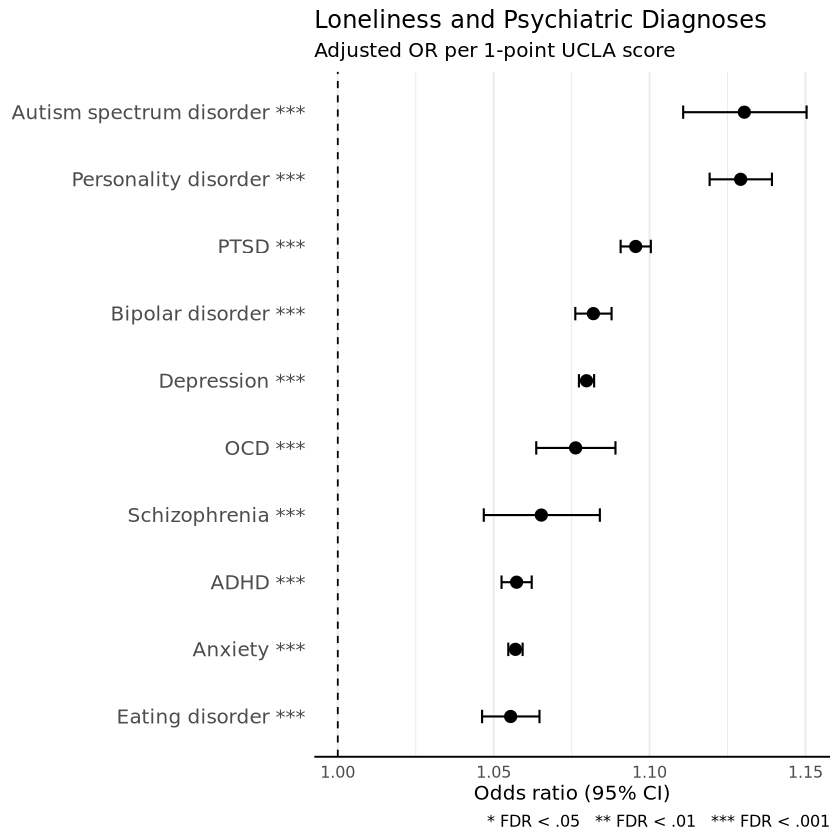

In [7]:
p_psych_or <- ggplot(
  psych_logistic_results,
  aes(
    x = OR,
    y = reorder(plot_label, OR)
  )
) +
  geom_vline(
    xintercept = 1,
    linetype = "dashed",
    linewidth = 0.5
  ) +
  geom_errorbarh(
    aes(
      xmin = CI_lower,
      xmax = CI_upper
    ),
    height = 0.2,
    linewidth = 0.6,
    color = "black"
  ) +
  geom_point(
    size = 3,
    color = "black"
  ) +
  labs(
    title = "Loneliness and Psychiatric Diagnoses",
    subtitle = "Adjusted OR per 1-point UCLA score",
    x = "Odds ratio (95% CI)",
    y = NULL,
    caption = "* FDR < .05   ** FDR < .01   *** FDR < .001"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    axis.line.x = element_line(),
    axis.text.y = element_text(size = 12)
    
  )

p_psych_or

In [8]:
# save fig
library(svglite)
ggsave(
  "p_psych_or.png",
  plot = p_psych_or,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_psych_or.svg",
  plot = p_psych_or,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


### Adjusting for all Psych Conditions


In [9]:
library(dplyr)
cohort <- cohort %>%
  mutate(
      loneliness_z = as.numeric(scale(total_score))
      )


In [10]:
model_psych_joint_z <- lm(
    loneliness_z ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_psych_joint_z)


Call:
lm(formula = loneliness_z ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = cohort)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.1302 -0.7137 -0.1082  0.6297  3.7260 

Coefficients:
                                   Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                       0.3025372  0.0120868   25.030  < 2e-16 ***
anxiety_psych_2plus               0.0359325  0.0067664    5.310 1.10e-07 ***
adhd_psych_2plus                  0.0427864  0.0118527    3.610 0.000306 ***
asd_psych_2plus                   0.3419121  0.0435751    7.847 4.30e-15 ***
bipolar_psych_2plus               0.1756990  0.0144749   12.138  < 2e-16 ***
eating_disorder_psych_2plus       0.0175789  0.0221228    0.795 0.42684

- loneliness no longer associated with:
    - eating disorder
    - ocd
    - schizophrenia
 

In [11]:
# plotting forest plot
library(broom)
library(dplyr)
library(ggplot2)

psych_forest <- tidy(
  model_psych_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_psych_2plus$", term))

In [12]:
psych_forest <- psych_forest %>%
  mutate(
    diagnosis = term %>%
      sub("_psych_2plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

`height` was translated to `width`.


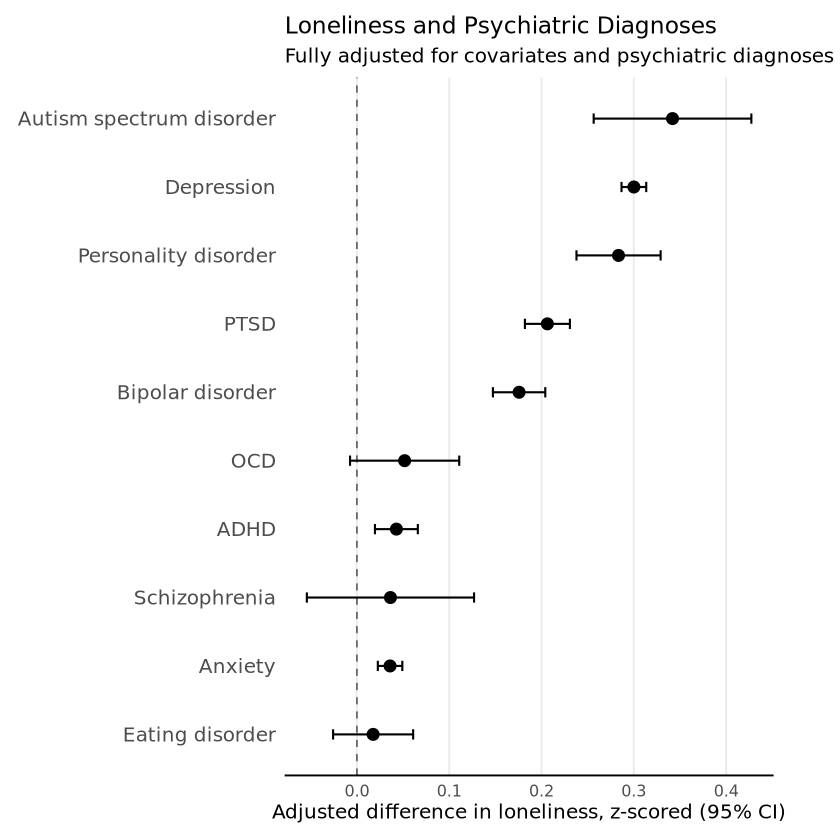

In [13]:
p_psych_joint_z <- ggplot(
  psych_forest,
  aes(
    x = estimate,
    y = reorder(diagnosis, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Psychiatric Diagnoses",
    subtitle = "Fully adjusted for covariates and psychiatric diagnoses",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12),
    axis.line.x = element_line(),
    plot.title = element_text(
        hjust = 0,
        size = 14),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
p_psych_joint_z

`height` was translated to `width`.


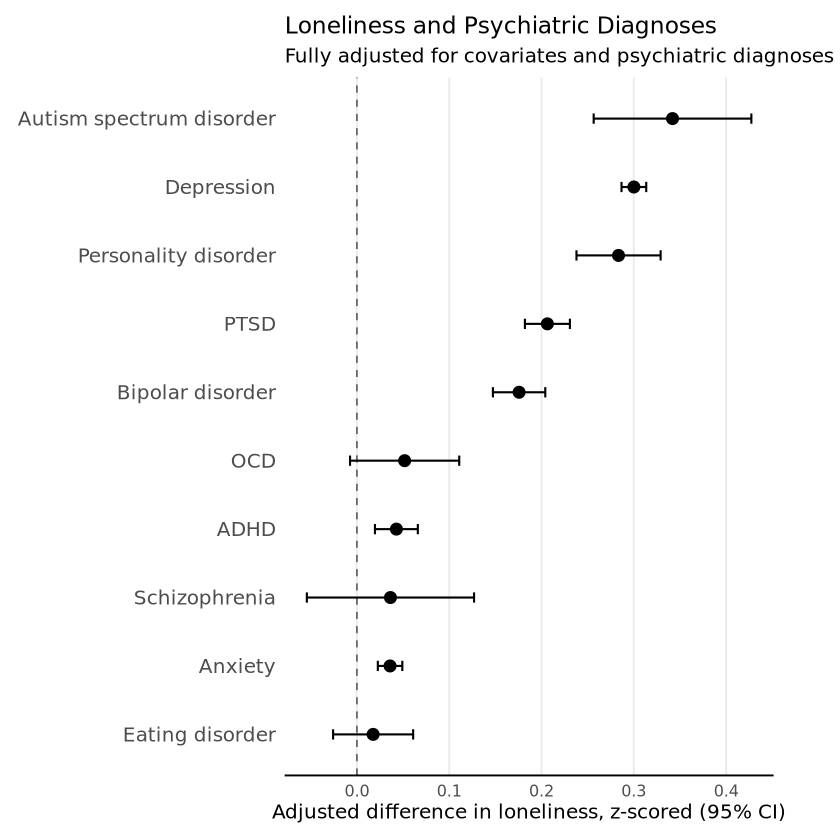

In [14]:
p_psych_joint_z

- adjusting for covariates, and comorbid psychiatric conditions, autism still increases loneliness by 0.35 standard deviations

### Raw Loneliness Model

In [15]:
model_psych_joint_raw <- lm(
    total_score ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_psych_joint_raw)


Call:
lm(formula = total_score ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = cohort)

Residuals:
     Min       1Q   Median       3Q      Max 
-16.7163  -3.8113  -0.5781   3.3629  19.8981 

Coefficients:
                                   Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                       9.1884458  0.0645476  142.351  < 2e-16 ***
anxiety_psych_2plus               0.1918916  0.0361351    5.310 1.10e-07 ***
adhd_psych_2plus                  0.2284938  0.0632976    3.610 0.000306 ***
asd_psych_2plus                   1.8259246  0.2327054    7.847 4.30e-15 ***
bipolar_psych_2plus               0.9382910  0.0773007   12.138  < 2e-16 ***
eating_disorder_psych_2plus       0.0938773  0.1181433    0.79

In [16]:
psych_forest_raw <- tidy(
  model_psych_joint_raw,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_psych_2plus$", term))

psych_forest_raw <- psych_forest_raw %>%
  mutate(
    diagnosis = term %>%
      sub("_psych_2plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

`height` was translated to `width`.


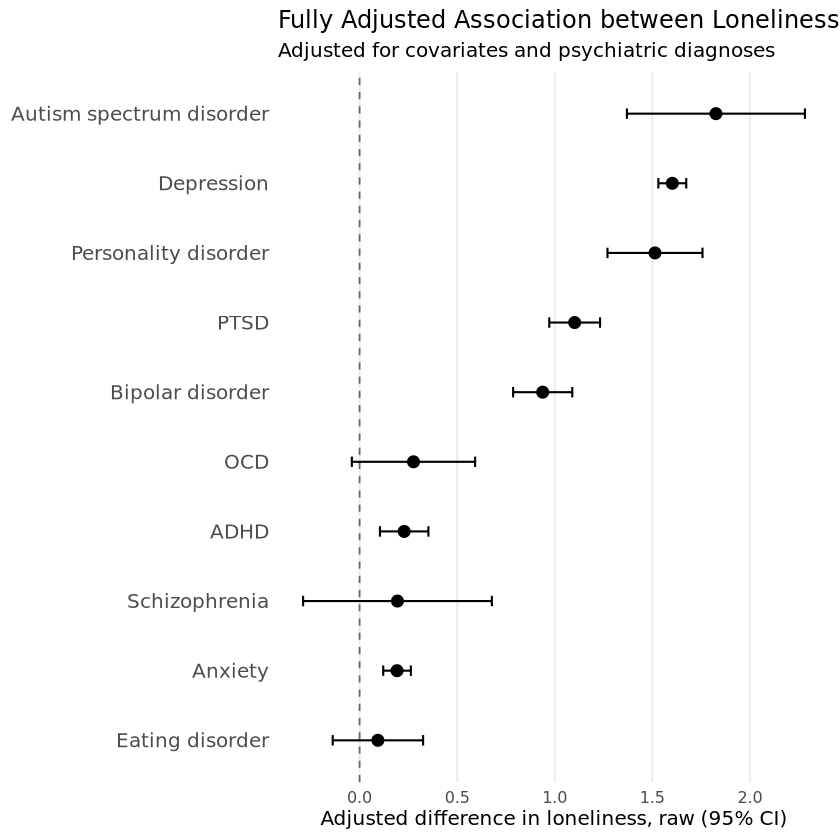

In [17]:
p_psych_joint_raw <- ggplot(
  psych_forest_raw,
  aes(
    x = estimate,
    y = reorder(diagnosis, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Fully Adjusted Association between Loneliness and Psychiatric Diagnoses",
    subtitle = "Adjusted for covariates and psychiatric diagnoses",
    x = "Adjusted difference in loneliness, raw (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12)
  )

p_psych_joint_raw

- autism increases loneliness score by 1.75 points, adjusting for covariates and comorbid diagnoses


In [18]:
install.packages("svglite")

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [19]:
# save fig
library(svglite)
ggsave(
  "p_psych_joint_z.png",
  plot = p_psych_joint_z,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_psych_joint_z.svg",
  plot = p_psych_joint_z,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [20]:
# Covariates
cov_forest <- tidy(
  model_psych_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term != "(Intercept)",
    !grepl("_psych_2plus$", term)
  )

In [21]:
cov_forest <- cov_forest %>%
  mutate(
    covariate = case_when(
      term == "age_at_ucla" ~ "Age",
      term == "sex_at_birthMale" ~ "Male sex",
      term == "income_c" ~ "Income",
      term == "bmi" ~ "BMI",
      term == "raceAsian" ~ "Race: Asian",
      term == "raceBlack or African American" ~ "Race: Black/African American",
      term == "raceAnother single population" ~ "Race: Another Single Population",
      term == "raceMore than one population" ~ "Race: Mixed/Multi",
      term == "raceNone of these" ~ "Race: None of these",
      TRUE ~ term
    )
  )

cov_forest <- cov_forest %>%
  filter(
    term != "(Intercept)",
    !grepl("_psych_2plus$", term),
    !term %in% c(
      "raceNone Indicated",
      "racePMI: Skip",
      "raceI prefer not to answer"
    )
  )

In [ ]:
head(cov_forest, 10)

`height` was translated to `width`.


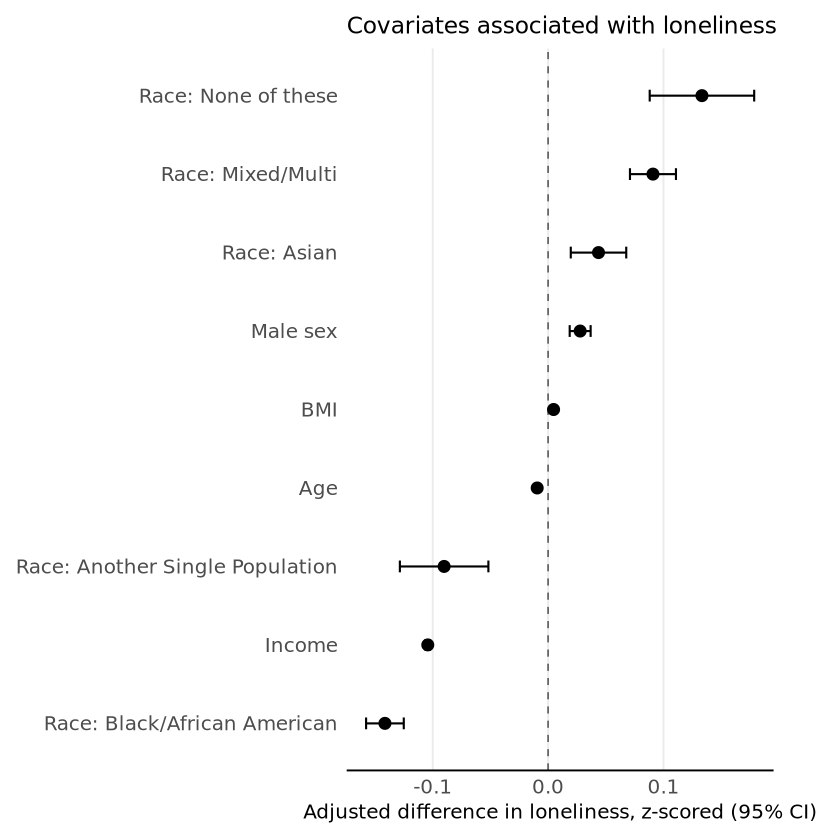

In [22]:
p_cov <- ggplot(
  cov_forest,
  aes(
    x = estimate,
    y = reorder(covariate, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Covariates associated with loneliness",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line.x = element_line(),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
    

p_cov

In [23]:
# save fig
library(svglite)
ggsave(
  "p_psych_cov_joint_z.png",
  plot = p_cov,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_psych_cov_joint_z.svg",
  plot = p_cov,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


### Loneliness and Immune Biomarkers (Std)

In [43]:
biomarkers <- c(
  "crp",
  "albumin",
  "basophils",
  "eosinophils",
  "leukocytes",
  "monocytes",
  "neutrophils",
  "platelets",
  "triglycerides"
)

# standardizing
dat <- cohort %>%
  mutate(
    loneliness_z = as.numeric(scale(total_score))
  )

for (bio in biomarkers) {
  dat[[paste0(bio, "_z")]] <- as.numeric(
    scale(dat[[bio]])
  )
}

In [25]:

biomarker_results <- map_dfr(
  biomarkers,
  function(bio) {

    outcome <- paste0(bio, "_z")

    formula <- as.formula(
      paste0(
        outcome,
        " ~ loneliness_z + age_at_ucla + sex_at_birth + ",
        "race + income_c + bmi"
      )
    )

    model <- lm(
      formula,
      data = dat
    )

    tidy(model, conf.int = TRUE) %>%
      filter(term == "loneliness_z") %>%
      mutate(
        biomarker = bio,
        N = nobs(model)
      )
  }
)

In [26]:
biomarker_results <- biomarker_results %>%
  mutate(
    p_fdr = p.adjust(
      p.value,
      method = "BH"
    ),
    fdr_significant = p_fdr < 0.05
  )

In [ ]:
names(biomarker_results)

In [27]:
biomarker_results %>%
  select(
    biomarker,
    N,
    estimate,
    conf.low,
    conf.high,
    p.value,
    p_fdr,
    fdr_significant
  ) %>%
  arrange(p_fdr)

biomarker,N,estimate,conf.low,conf.high,p.value,p_fdr,fdr_significant
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
platelets,63261,0.0342238009,0.026538797,0.041908805,2.641711e-18,2.377540e-17,TRUE
triglycerides,68132,0.0269682610,0.019407607,0.034528915,2.751154e-12,1.238019e-11,TRUE
leukocytes,59008,0.0124084895,0.004205912,0.020611067,3.027981e-03,9.083942e-03,TRUE
basophils,33722,0.0152841835,0.004399863,0.026168504,5.919980e-03,1.331995e-02,TRUE
eosinophils,36563,-0.0076867842,-0.017337876,0.001964308,1.185088e-01,1.845541e-01,FALSE
neutrophils,33797,0.0085627468,-0.002319987,0.019445481,1.230361e-01,1.845541e-01,FALSE
albumin,59624,0.0034963495,-0.004470533,0.011463232,3.896999e-01,5.010427e-01,FALSE
crp,12641,-0.0059366448,-0.022519712,0.010646422,4.828646e-01,5.432227e-01,FALSE
monocytes,35512,-0.0008011194,-0.011228202,0.009625963,8.802997e-01,8.802997e-01,FALSE


In [28]:
biomarker_results <- biomarker_results %>%
  mutate(
    p_fdr = p.adjust(p.value, method = "BH"),
    fdr_stars = case_when(
      p_fdr < 0.001 ~ "***",
      p_fdr < 0.01  ~ "**",
      p_fdr < 0.05  ~ "*",
      TRUE ~ ""
    )
  )

In [29]:
biomarker_results <- biomarker_results %>%
  mutate(
    fdr_stars = case_when(
      p_fdr < 0.001 ~ "***",
      p_fdr < 0.01  ~ "**",
      p_fdr < 0.05  ~ "*",
      TRUE ~ ""
    ),
    biomarker_label_fdr = if_else(
      fdr_stars == "",
      biomarker,
      paste0(biomarker, " ", fdr_stars)
    )
  )

`height` was translated to `width`.


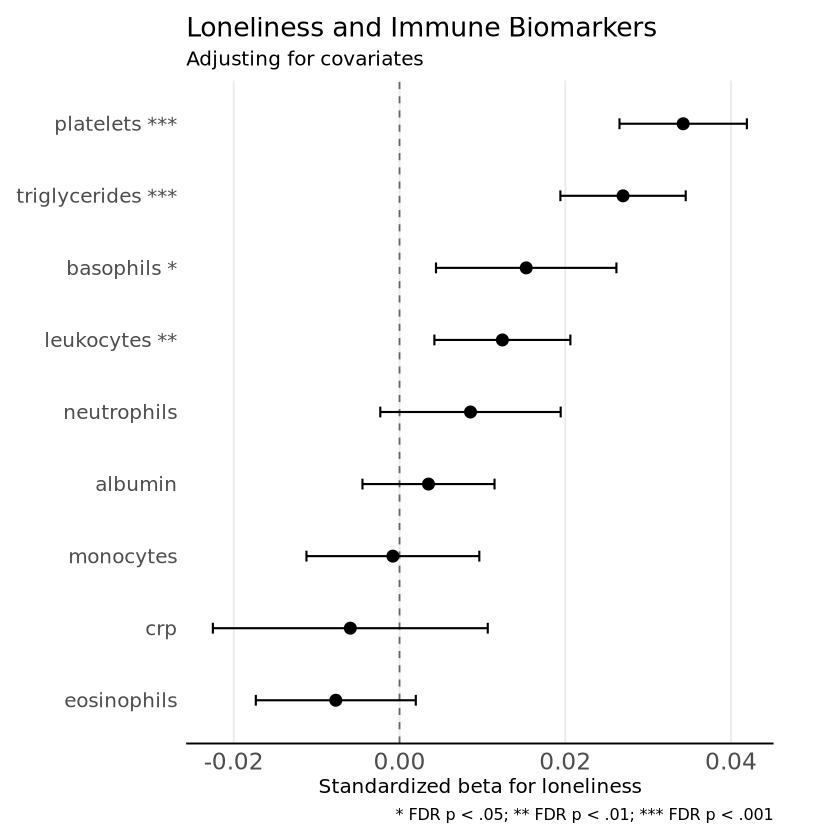

In [30]:
p_biomarker_z <- ggplot(
  biomarker_results,
  aes(
    x = estimate,
    y = reorder(biomarker_label_fdr, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Biomarkers",
    subtitle = "Adjusting for covariates",
    x = "Standardized beta for loneliness",
    y = NULL,
    caption = "* FDR p < .05; ** FDR p < .01; *** FDR p < .001"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 14),
    plot.title = element_text(size = 16, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line.x = element_line(),
    plot.margin = margin(10, 40, 10, 10),
    
  )

p_biomarker_z

In [31]:
# save fig
library(svglite)
ggsave(
  "p_biomarker_z.png",
  plot = p_biomarker_z,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_biomarker_z.svg",
  plot = p_biomarker_z,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [ ]:
### Fully adjusted associations between loneliness and immune biomarkers

In [32]:
model_biomarkers_joint_raw <- lm(
    total_score ~ basophils_z +
    leukocytes_z +
    platelets_z +
    triglycerides_z +
    age_at_ucla + 
    sex_at_birth +
    race +
    income_c +
    bmi,
    data = dat
)

summary(model_biomarkers_joint_raw)


Call:
lm(formula = total_score ~ basophils_z + leukocytes_z + platelets_z + 
    triglycerides_z + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-13.1593  -4.0085  -0.5373   3.6205  18.0258 

Coefficients:
                               Estimate Std. Error t value Pr(>|t|)    
(Intercept)                   10.855342   0.215004  50.489  < 2e-16 ***
basophils_z                    0.037684   0.038225   0.986 0.324210    
leukocytes_z                   0.057383   0.041016   1.399 0.161811    
platelets_z                    0.147394   0.038420   3.836 0.000125 ***
triglycerides_z                0.097706   0.034361   2.844 0.004466 ** 
age_at_ucla                   -0.068168   0.002436 -27.988  < 2e-16 ***
sex_at_birthMale               0.205150   0.073772   2.781 0.005426 ** 
raceAnother single population -0.515151   0.335911  -1.534 0.125144    
raceAsian                      0.054576   0.225666   0.242 0.808

- adjusting for all other FDR-sig biomarkers, loneliness significantly associated with platelets and triglycerides, mixed race, none of these races, income, bmi, age and se

In [33]:

immune_forest <- tidy(
  model_biomarkers_joint_raw,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_z$", term))

In [34]:
immune_forest <- immune_forest %>%
  mutate(
    biomarker = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

`height` was translated to `width`.


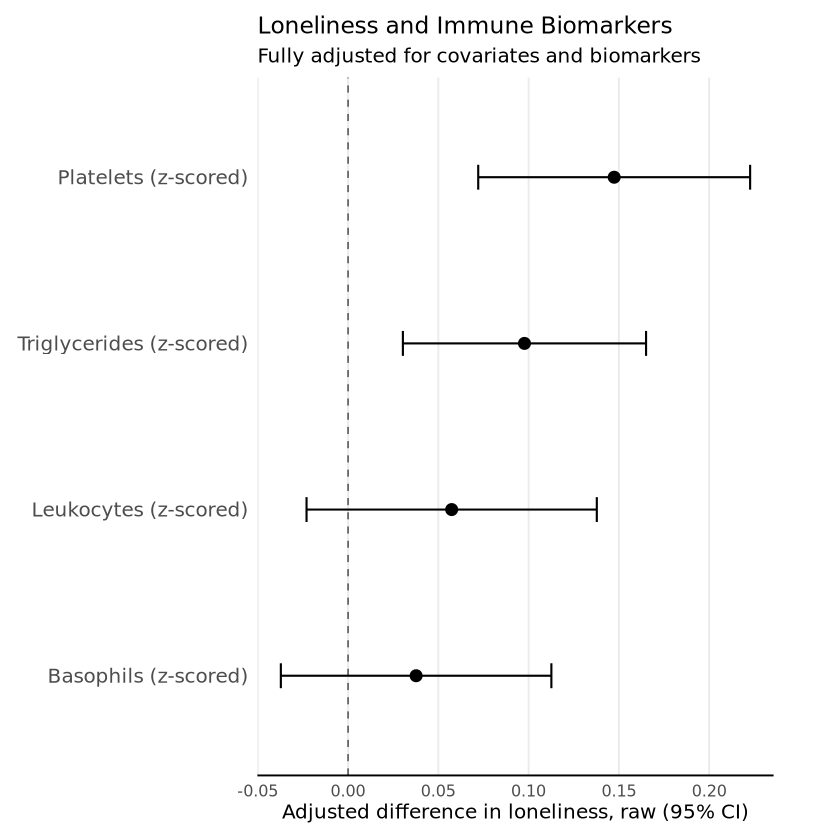

In [35]:
p_immune_joint_raw <- ggplot(
  immune_forest,
  aes(
    x = estimate,
    y = reorder(biomarker, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Biomarkers",
    subtitle = "Fully adjusted for covariates and biomarkers",
    x = "Adjusted difference in loneliness, raw (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12),
    axis.line.x = element_line(),
    plot.title = element_text(
        hjust = 0,
        size = 14),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
p_immune_joint_raw

In [ ]:
- 1 SD increase in platelets associated with 0.15-point increase in UCLA loneliness scale

In [ ]:
### Z-scored loneliness

In [36]:
model_biomarkers_joint_z <- lm(
    loneliness_z ~ basophils_z +
    leukocytes_z +
    platelets_z +
    triglycerides_z +
    age_at_ucla + 
    sex_at_birth +
    race +
    income_c +
    bmi,
    data = dat
)

summary(model_biomarkers_joint_z)


Call:
lm(formula = loneliness_z ~ basophils_z + leukocytes_z + platelets_z + 
    triglycerides_z + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = dat)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.4641 -0.7506 -0.1006  0.6780  3.3754 

Coefficients:
                                Estimate Std. Error t value Pr(>|t|)    
(Intercept)                    0.6146706  0.0402605  15.267  < 2e-16 ***
basophils_z                    0.0070566  0.0071577   0.986 0.324210    
leukocytes_z                   0.0107452  0.0076804   1.399 0.161811    
platelets_z                    0.0276001  0.0071942   3.836 0.000125 ***
triglycerides_z                0.0182959  0.0064342   2.844 0.004466 ** 
age_at_ucla                   -0.0127647  0.0004561 -27.988  < 2e-16 ***
sex_at_birthMale               0.0384153  0.0138141   2.781 0.005426 ** 
raceAnother single population -0.0964642  0.0629009  -1.534 0.125144    
raceAsian                      0.0102196  0.0422570   0.242 0.80

In [37]:

immune_forest_z <- tidy(
  model_biomarkers_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_z$", term))

In [38]:
immune_forest_z <- immune_forest_z %>%
  mutate(
    biomarker = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

`height` was translated to `width`.


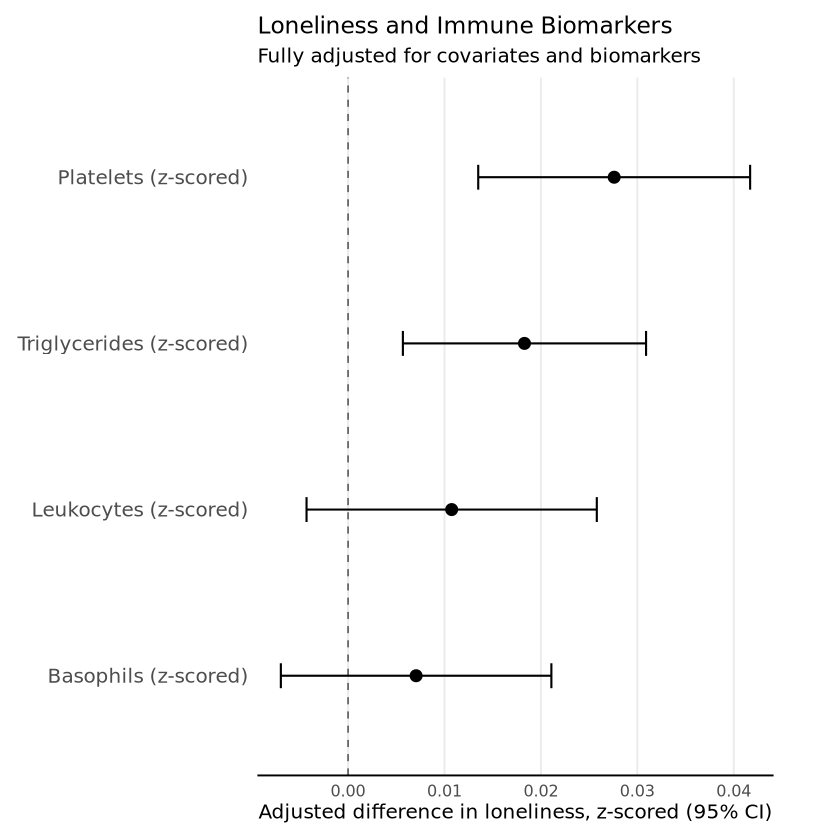

In [39]:
p_immune_joint_z <- ggplot(
  immune_forest_z,
  aes(
    x = estimate,
    y = reorder(biomarker, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Biomarkers",
    subtitle = "Fully adjusted for covariates and biomarkers",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12),
    axis.line.x = element_line(),
    plot.title = element_text(
        hjust = 0,
        size = 14),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
p_immune_joint_z

In [40]:
# save fig
library(svglite)
ggsave(
  "p_immune_joint_z.png",
  plot = p_immune_joint_z,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_immune_joint_z.svg",
  plot = p_immune_joint_z,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [ ]:
## Immune Conditions and loneliness

In [41]:
# raw loneliness
immune_conditions <- c("asthma", "allergic_rhinitis", "rheumatoid_arthritis",
                       "hypothyroidism", "ulcerative_colitis", "type2_diabetes",
                       "crohns_disease", "atopic_dermatitis")

immune_logistic_results <- data.frame()

for (dx in immune_conditions) {

  f <- as.formula(
    paste0(
      dx,
      " ~ total_score + age_at_ucla + sex_at_birth + ",
      "race + income_c + bmi"
    )
  )

  model <- glm(
    f,
    data = cohort,
    family = binomial(link = "logit"),
    na.action = na.omit
  )

  s <- summary(model)

  beta <- s$coefficients["total_score", "Estimate"]
  se   <- s$coefficients["total_score", "Std. Error"]
  p    <- s$coefficients["total_score", "Pr(>|z|)"]

  # Model fit indices
  aic <- AIC(model)

  null_dev <- model$null.deviance
  resid_dev <- model$deviance

  # Likelihood-ratio test comparing full model to intercept-only model
  lr_stat <- null_dev - resid_dev
  lr_df <- model$df.null - model$df.residual
  lr_p <- pchisq(
    lr_stat,
    df = lr_df,
    lower.tail = FALSE
 )

  # McFadden pseudo-R2
  mcfadden_r2 <- 1 - (resid_dev / null_dev)

  # Tjur R2
  pred_prob <- fitted(model)

  tjur_r2 <-
    mean(pred_prob[model$y == 1], na.rm = TRUE) -
    mean(pred_prob[model$y == 0], na.rm = TRUE)

  immune_logistic_results <- rbind(
  immune_logistic_results,
  data.frame(
    condition = dx,
    N = nobs(model),
    N_cases = sum(model$y == 1),

    beta_logodds = beta,
    OR = exp(beta),
    CI_lower = exp(beta - 1.96 * se),
    CI_upper = exp(beta + 1.96 * se),
    p_value = p,

    AIC = aic,
    null_deviance = null_dev,
    residual_deviance = resid_dev,

    LR_chisq = lr_stat,
    LR_df = lr_df,
    LR_p = lr_p,

    McFadden_R2 = mcfadden_r2,
    Tjur_R2 = tjur_r2
    )
  )
}

In [42]:
# FDR
immune_logistic_results <- immune_logistic_results %>%
  mutate(
    FDR = p.adjust(p_value, method = "BH"),

    condition_label = recode(
      condition,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic Rhinitis",
      rheumatoid_arthritis = "Rheumatoid Arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative Colitis",
      type2_diabetes = "Type 2 Diabetes",
      crohns_disease = "Crohn's Disease",
      atopic_dermatitis = "Atopic Dermatitis"
    ),

    stars = case_when(
      FDR < 0.001 ~ "***",
      FDR < 0.01  ~ "**",
      FDR < 0.05  ~ "*",
      TRUE ~ ""
    ),

    plot_label = ifelse(
      stars == "",
      condition_label,
      paste0(condition_label, " ", stars)
    )
  ) %>%
  arrange(OR)

immune_logistic_results

condition,N,N_cases,beta_logodds,OR,CI_lower,CI_upper,p_value,AIC,null_deviance,residual_deviance,LR_chisq,LR_df,LR_p,McFadden_R2,Tjur_R2,FDR,condition_label,stars,plot_label
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ulcerative_colitis,183204,1679,0.01121075,1.011274,1.001631,1.021009,2.182145e-02,18968.32,19099.65,18940.32,159.3316,13,2.691567e-27,0.008342121,0.0007543542,2.182145e-02,Ulcerative Colitis,*,Ulcerative Colitis *
crohns_disease,183204,1606,0.01180786,1.011878,1.002094,1.021757,1.722014e-02,18282.89,18412.65,18254.89,157.7614,13,5.592705e-27,0.008568097,0.0007368375,1.968016e-02,Crohn's Disease,*,Crohn's Disease *
atopic_dermatitis,183204,4592,0.01226790,1.012343,1.006514,1.018207,3.132835e-05,42798.70,42922.77,42770.70,152.0640,13,7.908919e-26,0.003542737,0.0008130516,4.177113e-05,Atopic Dermatitis,***,Atopic Dermatitis ***
allergic_rhinitis,183204,34046,0.01238858,1.012466,1.010091,1.014846,4.695826e-25,173701.84,175923.21,173673.84,2249.3746,13,0.000000e+00,0.012786116,0.0117257112,1.252220e-24,Allergic Rhinitis,***,Allergic Rhinitis ***
hypothyroidism,183204,23347,0.01472185,1.014831,1.011972,1.017697,1.468146e-24,130076.15,139779.40,130048.15,9731.2552,13,0.000000e+00,0.069618663,0.0525127866,2.936291e-24,Hypothyroidism,***,Hypothyroidism ***
type2_diabetes,183204,22212,0.01825833,1.018426,1.015499,1.021361,1.681993e-35,118884.74,135348.22,118856.74,16491.4759,13,0.000000e+00,0.121844793,0.0944166237,6.727973e-35,Type 2 Diabetes,***,Type 2 Diabetes ***
asthma,183204,25305,0.02168544,1.021922,1.019255,1.024597,1.850940e-59,143087.48,147129.17,143059.48,4069.6859,13,0.000000e+00,0.027660633,0.0235048106,1.480752e-58,Asthma,***,Asthma ***
rheumatoid_arthritis,183204,4122,0.02575510,1.026090,1.019941,1.032275,4.491861e-17,37943.88,39430.45,37915.88,1514.5677,13,3.130952e-316,0.038411120,0.0083609796,7.186977e-17,Rheumatoid Arthritis,***,Rheumatoid Arthritis ***


`height` was translated to `width`.


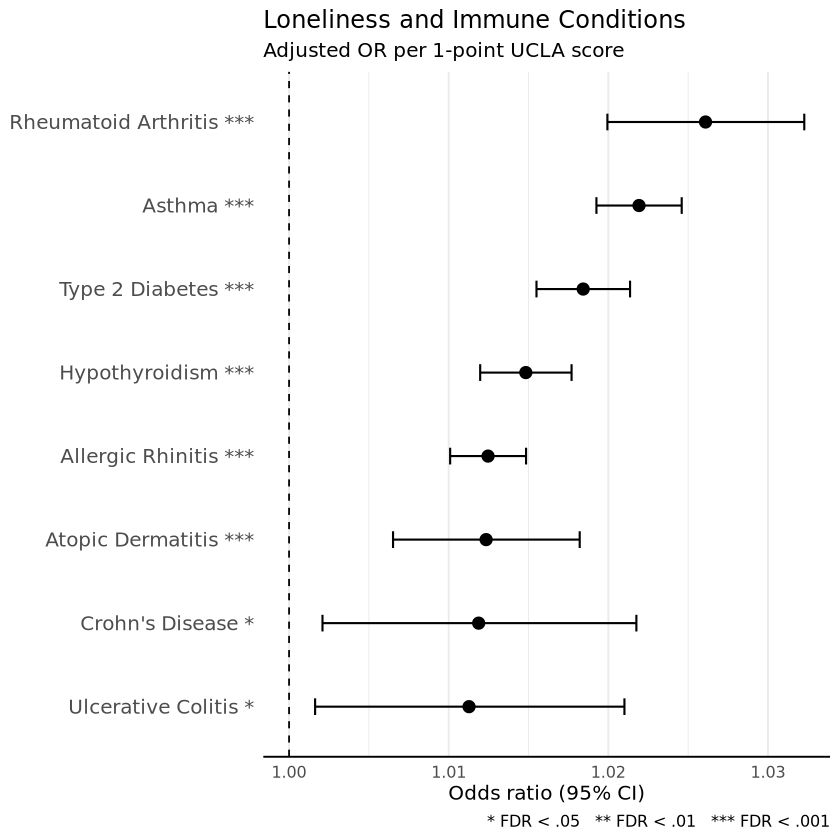

In [43]:
p_immune_or <- ggplot(
  immune_logistic_results,
  aes(
    x = OR,
    y = reorder(plot_label, OR)
  )
) +
  geom_vline(
    xintercept = 1,
    linetype = "dashed",
    linewidth = 0.5
  ) +
  geom_errorbarh(
    aes(
      xmin = CI_lower,
      xmax = CI_upper
    ),
    height = 0.2,
    linewidth = 0.6,
    color = "black"
  ) +
  geom_point(
    size = 3,
    color = "black"
  ) +
  labs(
    title = "Loneliness and Immune Conditions",
    subtitle = "Adjusted OR per 1-point UCLA score",
    x = "Odds ratio (95% CI)",
    y = NULL,
    caption = "* FDR < .05   ** FDR < .01   *** FDR < .001"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    axis.line.x = element_line(),
    axis.text.y = element_text(size = 12)
    
  )

p_immune_or

In [44]:
# save fig
library(svglite)
ggsave(
  "p_immune_or.png",
  plot = p_immune_or,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_immune_or.svg",
  plot = p_immune_or,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [45]:
model_immune_conditions_joint_z <- lm(
    loneliness_z ~ 
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_immune_conditions_joint_z)


Call:
lm(formula = loneliness_z ~ asthma + allergic_rhinitis + rheumatoid_arthritis + 
    hypothyroidism + ulcerative_colitis + type2_diabetes + crohns_disease + 
    atopic_dermatitis + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = cohort)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.3825 -0.7289 -0.1116  0.6412  3.6762 

Coefficients:
                                Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                    3.890e-01  1.241e-02   31.348  < 2e-16 ***
asthma                         8.431e-02  6.848e-03   12.312  < 2e-16 ***
allergic_rhinitis              2.075e-02  6.066e-03    3.421 0.000625 ***
rheumatoid_arthritis           8.961e-02  1.496e-02    5.991 2.09e-09 ***
hypothyroidism                 4.077e-02  6.878e-03    5.927 3.10e-09 ***
ulcerative_colitis             1.807e-02  2.367e-02    0.763 0.445181    
type2_diabetes                 5.441e-02  7.170e-03    7.589 3.24e-14 ***
crohns_disease                 2.467e-

- loneliness associated with allergic rhinitis, rheumatoid arthritis, hypothyroidism, type 2 diabetes after accounting for comorbidity and covariates

In [46]:
immune_condition_forest_z <- tidy(
  model_immune_conditions_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term %in% c(
      "asthma",
      "allergic_rhinitis",
      "rheumatoid_arthritis",
      "hypothyroidism",
      "ulcerative_colitis",
      "type2_diabetes",
      "crohns_disease",
      "atopic_dermatitis"
    )
  )

In [47]:
immune_condition_forest_z <- immune_condition_forest_z %>%
  mutate(
    condition = recode(
      term,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic rhinitis",
      rheumatoid_arthritis = "Rheumatoid arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative colitis",
      type2_diabetes = "Type 2 diabetes",
      crohns_disease = "Crohn's disease",
      atopic_dermatitis = "Atopic dermatitis"
    )
  )

`height` was translated to `width`.


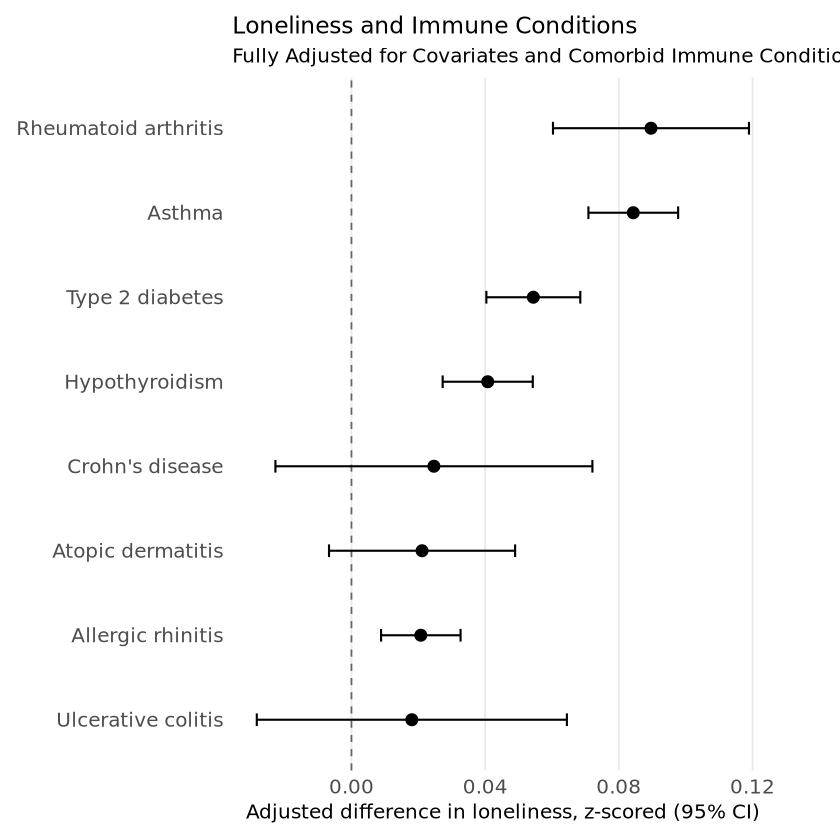

In [48]:
p_immune_conditions <- ggplot(
  immune_condition_forest_z,
  aes(
    x = estimate,
    y = reorder(condition, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Conditions",
    subtitle = "Fully Adjusted for Covariates and Comorbid Immune Conditions",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(10, 40, 10, 10)
  )

p_immune_conditions

In [49]:
# save fig
library(svglite)
ggsave(
  "p_immune_conditions_z.png",
  plot = p_immune_conditions,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_immune_conditions_z.svg",
  plot = p_immune_conditions,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [50]:
model_immune_conditions_joint_raw <- lm(
    total_score ~ 
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_immune_conditions_joint_raw)


Call:
lm(formula = total_score ~ asthma + allergic_rhinitis + rheumatoid_arthritis + 
    hypothyroidism + ulcerative_colitis + type2_diabetes + crohns_disease + 
    atopic_dermatitis + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = cohort)

Residuals:
     Min       1Q   Median       3Q      Max 
-12.7232  -3.8925  -0.5962   3.4240  19.6319 

Coefficients:
                                Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                    9.6503111  0.0662724  145.616  < 2e-16 ***
asthma                         0.4502519  0.0365709   12.312  < 2e-16 ***
allergic_rhinitis              0.1108188  0.0323965    3.421 0.000625 ***
rheumatoid_arthritis           0.4785371  0.0798733    5.991 2.09e-09 ***
hypothyroidism                 0.2177001  0.0367321    5.927 3.10e-09 ***
ulcerative_colitis             0.0964936  0.1263872    0.763 0.445181    
type2_diabetes                 0.2905640  0.0382882    7.589 3.24e-14 ***
crohns_disease               

In [51]:
# Fully adjusted model (pruning n.s.)

full_family_model_z <- lm(
    loneliness_z ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        basophils_z +
        leukocytes_z +
        platelets_z +
        triglycerides_z +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = dat
    )

summary(full_family_model_z)


Call:
lm(formula = loneliness_z ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + asthma + allergic_rhinitis + 
    rheumatoid_arthritis + hypothyroidism + ulcerative_colitis + 
    type2_diabetes + crohns_disease + atopic_dermatitis + basophils_z + 
    leukocytes_z + platelets_z + triglycerides_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-3.11245 -0.71004 -0.08909  0.63859  3.15301 

Coefficients:
                                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)                       0.3036330  0.0413239   7.348 2.09e-13 ***
anxiety_psych_2plus               0.1062527  0.0161872   6.564 5.35e-11 ***
adhd_psych_2plus                  0.0793111  0.0258957   3.063 0.002196 ** 
as

- anxiety, adhd, asd, bipolar, depression, personality disorder, ptsd, asthma, allergic rhinitis, platelets, age, sex, asian race, mixed race, none of these races, white race, income and bmi remain associated in the full model

In [52]:
full_joint_forest_z <- tidy(
  full_family_model_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term %in% c(
      "asthma",
      "allergic_rhinitis",
      "rheumatoid_arthritis",
      "hypothyroidism",
      "ulcerative_colitis",
      "type2_diabetes",
      "crohns_disease",
      "atopic_dermatitis",
      "basophils_z",
      "leukocytes_z",
      "platelets_z",
      "triglycerides_z",
      "anxiety_psych_2plus",
      "adhd_psych_2plus",
      "asd_psych_2plus", 
      "bipolar_psych_2plus" ,
      "eating_disorder_psych_2plus",
      "depression_psych_2plus", 
      "ocd_psych_2plus",
      "personality_disorder_psych_2plus",
      "ptsd_psych_2plus",
      "schizophrenia_psych_2plus"  
    )
  )

full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    term = recode(
      term,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic rhinitis",
      rheumatoid_arthritis = "Rheumatoid arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative colitis",
      type2_diabetes = "Type 2 diabetes",
      crohns_disease = "Crohn's disease",
      atopic_dermatitis = "Atopic dermatitis",
      
    )
  )

full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    term = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    term = term %>%
      sub("_psych_2plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

In [53]:
full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    stars = case_when(
      p.value < 0.001 ~ "***",
      p.value < 0.01  ~ "**",
      p.value < 0.05  ~ "*",
      TRUE ~ ""
    ),
    plot_label = ifelse(
      stars == "",
      term,
      paste0(term, " ", stars)
    )
  )

`height` was translated to `width`.


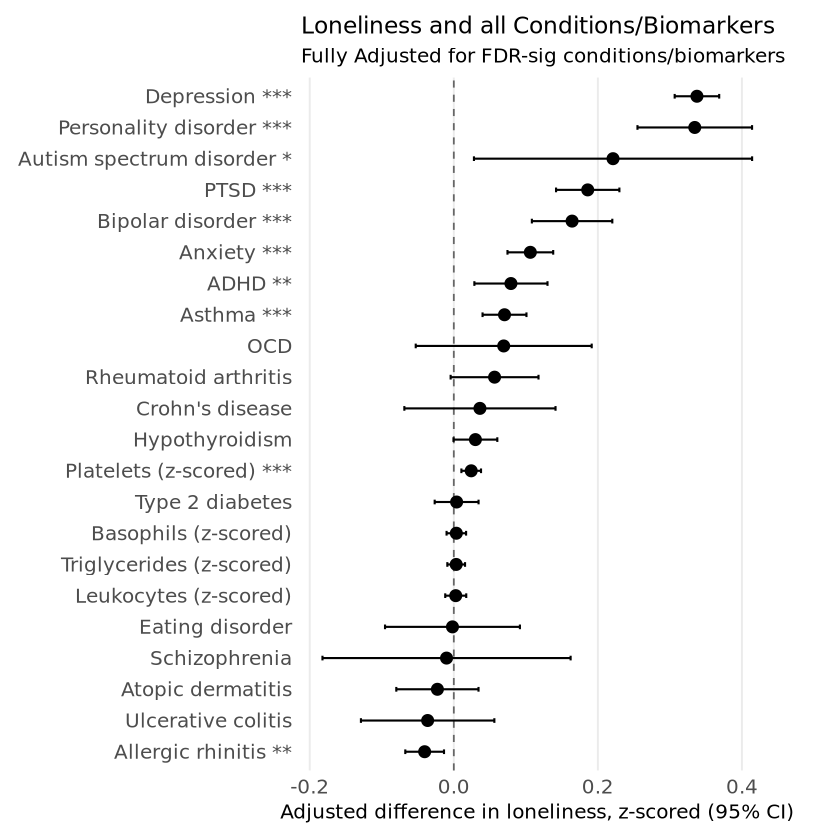

In [54]:
p_full_joint <- ggplot(
  full_joint_forest_z,
  aes(
    x = estimate,
    y = reorder(plot_label, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and all Conditions/Biomarkers",
    subtitle = "Fully Adjusted for FDR-sig conditions/biomarkers",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(10, 40, 10, 10)
  )

p_full_joint

In [55]:
# save fig
library(svglite)
ggsave(
  "p_full_joint_z.png",
  plot = p_full_joint,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_full_joint_z.svg",
  plot = p_full_joint,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


- strongest association with loneliness is depression (1.8 ish raw increase in UCLA loneliness scale), 0.4 SD increase
- platelets only remaining immune biomarker

In [56]:
full_family_model_raw <- lm(
    total_score ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        basophils_z +
        leukocytes_z +
        platelets_z +
        triglycerides_z +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = dat
    )

summary(full_family_model_raw)


Call:
lm(formula = total_score ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + asthma + allergic_rhinitis + 
    rheumatoid_arthritis + hypothyroidism + ulcerative_colitis + 
    type2_diabetes + crohns_disease + atopic_dermatitis + basophils_z + 
    leukocytes_z + platelets_z + triglycerides_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-16.6215  -3.7919  -0.4757   3.4103  16.8381 

Coefficients:
                                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)                       9.194297   0.220684  41.663  < 2e-16 ***
anxiety_psych_2plus               0.567425   0.086445   6.564 5.35e-11 ***
adhd_psych_2plus                  0.423548   0.138292   3.063 0.002196 ** 
asd_psy

In [57]:
### Replicating with 1 Diagnosis
full_family_model_1plus_z <- lm(
    loneliness_z ~ 
        anxiety_psych_1plus +
        adhd_psych_1plus +
        asd_psych_1plus + 
        bipolar_psych_1plus +
        eating_disorder_psych_1plus +
        depression_psych_1plus +
        ocd_psych_1plus +
        personality_disorder_psych_1plus +
        ptsd_psych_1plus +
        schizophrenia_psych_1plus +
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        basophils_z +
        leukocytes_z +
        platelets_z +
        triglycerides_z +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = dat
    )

summary(full_family_model_1plus_z)


Call:
lm(formula = loneliness_z ~ anxiety_psych_1plus + adhd_psych_1plus + 
    asd_psych_1plus + bipolar_psych_1plus + eating_disorder_psych_1plus + 
    depression_psych_1plus + ocd_psych_1plus + personality_disorder_psych_1plus + 
    ptsd_psych_1plus + schizophrenia_psych_1plus + asthma + allergic_rhinitis + 
    rheumatoid_arthritis + hypothyroidism + ulcerative_colitis + 
    type2_diabetes + crohns_disease + atopic_dermatitis + basophils_z + 
    leukocytes_z + platelets_z + triglycerides_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = dat)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.1173 -0.7089 -0.0876  0.6399  3.1796 

Coefficients:
                                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)                       0.2140759  0.0417378   5.129 2.94e-07 ***
anxiety_psych_1plus               0.1069189  0.0156471   6.833 8.52e-12 ***
adhd_psych_1plus                  0.1006592  0.0231461   4.349 1.37e-05 ***
asd_psych_1p

In [58]:
full_joint_forest_1plus_z <- tidy(
  full_family_model_1plus_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term %in% c(
      "asthma",
      "allergic_rhinitis",
      "rheumatoid_arthritis",
      "hypothyroidism",
      "ulcerative_colitis",
      "type2_diabetes",
      "crohns_disease",
      "atopic_dermatitis",
      "basophils_z",
      "leukocytes_z",
      "platelets_z",
      "triglycerides_z",
      "anxiety_psych_1plus",
      "adhd_psych_1plus",
      "asd_psych_1plus", 
      "bipolar_psych_1plus" ,
      "eating_disorder_psych_1plus",
      "depression_psych_1plus", 
      "ocd_psych_1plus",
      "personality_disorder_psych_1plus",
      "ptsd_psych_1plus",
      "schizophrenia_psych_1plus"  
    )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    term = recode(
      term,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic rhinitis",
      rheumatoid_arthritis = "Rheumatoid arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative colitis",
      type2_diabetes = "Type 2 diabetes",
      crohns_disease = "Crohn's disease",
      atopic_dermatitis = "Atopic dermatitis",
      
    )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    term = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    term = term %>%
      sub("_psych_1plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    stars = case_when(
      p.value < 0.001 ~ "***",
      p.value < 0.01  ~ "**",
      p.value < 0.05  ~ "*",
      TRUE ~ ""
    ),
    plot_label = ifelse(
      stars == "",
      term,
      paste0(term, " ", stars)
    )
  )

`height` was translated to `width`.


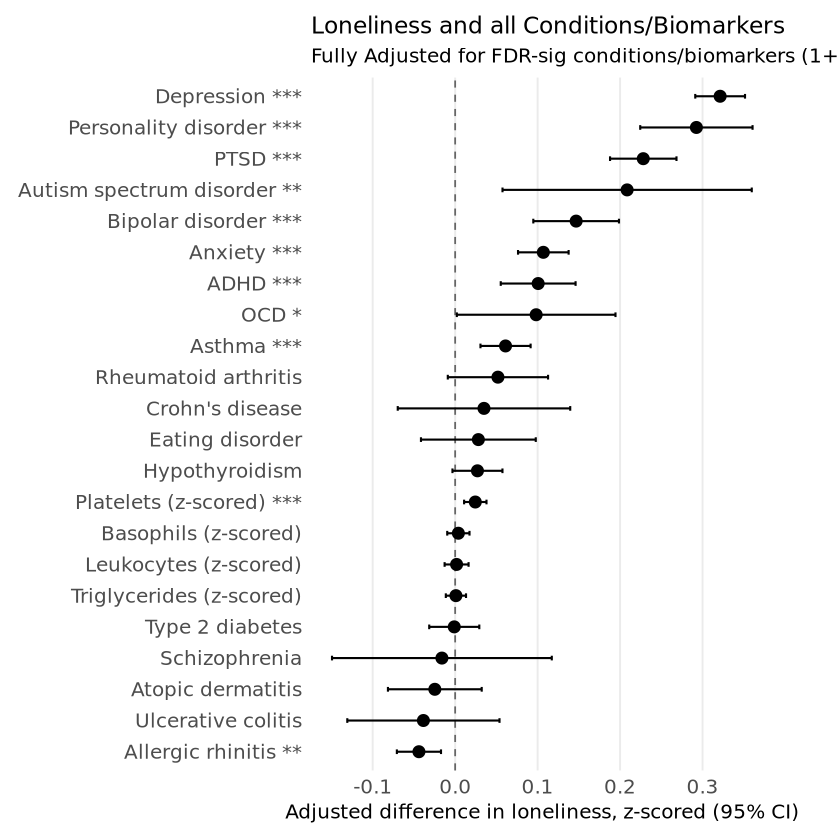

In [59]:
p_full_joint_1plus <- ggplot(
  full_joint_forest_1plus_z,
  aes(
    x = estimate,
    y = reorder(plot_label, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and all Conditions/Biomarkers",
    subtitle = "Fully Adjusted for FDR-sig conditions/biomarkers (1+ Diagnosis Instance for Psych)",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(10, 40, 10, 10)
  )

p_full_joint_1plus

In [60]:
binary_vars <- c(
  # Immune conditions
  "asthma",
  "allergic_rhinitis",
  "rheumatoid_arthritis",
  "hypothyroidism",
  "ulcerative_colitis",
  "type2_diabetes",
  "crohns_disease",
  "atopic_dermatitis",

  # Psychiatric diagnoses (2+ diagnosis dates)
  "anxiety_psych_1plus",
  "depression_psych_1plus",
  "ptsd_psych_1plus",
  "adhd_psych_1plus",
  "asd_psych_1plus",
  "bipolar_psych_1plus",
  "eating_disorder_psych_1plus",
  "ocd_psych_1plus",
  "personality_disorder_psych_1plus",
  "schizophrenia_psych_1plus"
)

In [61]:
analysis_dat <- model.frame(full_family_model_1plus_z)

sample_size_table <- tibble(
  variable = binary_vars,
  N_total = nrow(analysis_dat),
  N_cases = sapply(
    binary_vars,
    function(v) sum(analysis_dat[[v]] == 1, na.rm = TRUE)
  ),
  N_noncases = sapply(
    binary_vars,
    function(v) sum(analysis_dat[[v]] == 0, na.rm = TRUE)
  )
) %>%
  mutate(
    prevalence_pct = 100 * N_cases / N_total
  )

sample_size_table

variable,N_total,N_cases,N_noncases,prevalence_pct
<chr>,<int>,<int>,<int>,<dbl>
asthma,22761,5178,17583,22.7494398
allergic_rhinitis,22761,7654,15107,33.6276965
rheumatoid_arthritis,22761,947,21814,4.1606256
hypothyroidism,22761,4913,17848,21.5851676
ulcerative_colitis,22761,418,22343,1.8364747
type2_diabetes,22761,5698,17063,25.0340495
crohns_disease,22761,324,22437,1.4234875
atopic_dermatitis,22761,1092,21669,4.7976802
anxiety_psych_1plus,22761,11350,11411,49.8659989


In [62]:
### Exporting Linear Model Results

library(broom)
library(dplyr)
library(purrr)

export_lm_results <- function(model, model_name) {

  N_model <- nrow(model.frame(model))
  outcome_name <- all.vars(formula(model))[1]

  coef_tab <- broom::tidy(
    model,
    conf.int = TRUE,
    conf.level = 0.95
  ) %>%
    mutate(
      model_name = model_name,
      model_type = "linear",
      outcome = outcome_name,
      N = N_model
    ) %>%
    select(
      model_name,
      model_type,
      outcome,
      N,
      term,
      estimate,
      std.error,
      conf.low,
      conf.high,
      statistic,
      p.value
    )

  fit_tab <- broom::glance(model) %>%
    mutate(
      model_name = model_name,
      model_type = "linear",
      outcome = outcome_name,
      N = N_model
    )

  list(
    coefficients = coef_tab,
    fit = fit_tab
  )
}

In [63]:
### Exporting Logistic Model Results

export_glm_results <- function(model, model_name) {

  N_model <- nrow(model.frame(model))
  outcome_name <- all.vars(formula(model))[1]

  coef_tab <- broom::tidy(
    model,
    conf.int = TRUE,
    conf.level = 0.95
  ) %>%
    mutate(
      model_name = model_name,
      model_type = "logistic",
      outcome = outcome_name,
      N = N_model,
      OR = exp(estimate),
      OR_low = exp(conf.low),
      OR_high = exp(conf.high)
    ) %>%
    select(
      model_name,
      model_type,
      outcome,
      N,
      term,
      estimate,
      std.error,
      conf.low,
      conf.high,
      OR,
      OR_low,
      OR_high,
      statistic,
      p.value
    )

  fit_tab <- broom::glance(model) %>%
    mutate(
      model_name = model_name,
      model_type = "logistic",
      outcome = outcome_name,
      N = N_model
    )

  list(
    coefficients = coef_tab,
    fit = fit_tab
  )
}

In [ ]:
class(full_family_model_raw)

In [64]:
### Run on fitted models

psych_joint_out_z <- export_lm_results(
  model_psych_joint_z,
  "Psychiatric conditions joint model (z-scored)"
)

psych_joint_out_raw <- export_lm_results(
  model_psych_joint_raw,
  "Psychiatric conditions joint model (raw)"
)

immune_joint_out_z <- export_lm_results(
  model_immune_conditions_joint_z,
  "Immune conditions joint model (z-scored)"
)

immune_joint_out_raw <- export_lm_results(
  model_immune_conditions_joint_raw,
  "Immune conditions joint model (raw)"
)

full_joint_out_z <- export_lm_results(
  full_family_model_z,
  "Psychiatric + immune conditions joint model (z-scored)"
)

full_joint_out_raw <- export_lm_results(
  full_family_model_raw,
  "Psychiatric + immune conditions joint model (raw)"
)

In [65]:
psych_joint_out_z$coefficients
psych_joint_out_z$fit

model_name,model_type,outcome,N,term,estimate,std.error,conf.low,conf.high,statistic,p.value
<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,(Intercept),0.302537243,0.0120868112,0.278847372,0.326227114,25.0303606,4.884130e-138
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,anxiety_psych_2plus,0.035932520,0.0067664450,0.022670444,0.049194596,5.3103987,1.095128e-07
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,adhd_psych_2plus,0.042786436,0.0118527406,0.019555338,0.066017534,3.6098348,3.064737e-04
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,asd_psych_2plus,0.341912113,0.0435750728,0.256505975,0.427318250,7.8465070,4.300750e-15
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,bipolar_psych_2plus,0.175698975,0.0144748885,0.147328527,0.204069422,12.1381920,6.829341e-34
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,eating_disorder_psych_2plus,0.017578929,0.0221228342,-0.025781316,0.060939173,0.7946056,4.268440e-01
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,depression_psych_2plus,0.300042259,0.0068328322,0.286650065,0.313434453,43.9118434,0.000000e+00
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,ocd_psych_2plus,0.051719128,0.0301759371,-0.007425013,0.110863269,1.7139195,8.654520e-02
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,personality_disorder_psych_2plus,0.283442500,0.0232541086,0.237864984,0.329020017,12.1889213,3.671366e-34


r.squared,adj.r.squared,sigma,statistic,p.value,df,logLik,AIC,BIC,deviance,df.residual,nobs,model_name,model_type,outcome,N
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>,<chr>,<int>
0.1445639,0.1444612,0.9247149,1407.116,0,22,-245604.4,491256.8,491499.6,156637.6,183181,183204,Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204


In [66]:
# giant table
all_coefficients <- bind_rows(
  psych_joint_out_z$coefficients,
  psych_joint_out_raw$coefficients,
  immune_joint_out_z$coefficients,
  immune_joint_out_raw$coefficients,
  full_joint_out_z$coefficients,
  full_joint_out_raw$coefficients
)

all_model_fit <- bind_rows(
  psych_joint_out_z$fit,
  psych_joint_out_raw$fit,
  immune_joint_out_z$fit,
  immune_joint_out_raw$fit,
  full_joint_out_z$fit,
  full_joint_out_raw$fit
)

In [67]:
all_coefficients <- all_coefficients %>%
  mutate(
    estimate_ci = sprintf(
      "%.3f [%.3f, %.3f]",
      estimate,
      conf.low,
      conf.high
    ),
    p_display = case_when(
      p.value < 0.001 ~ "<0.001",
      TRUE ~ sprintf("%.3f", p.value)
    )
  )

In [68]:
write.csv(
  all_coefficients,
  "regression_coefficients_all_models.csv",
  row.names = FALSE
)

write.csv(
  all_model_fit,
  "regression_model_fit_all_models.csv",
  row.names = FALSE
)

saveRDS(
  all_coefficients,
  "regression_coefficients_all_models.rds"
)

saveRDS(
  all_model_fit,
  "regression_model_fit_all_models.rds"
)

In [69]:
system(
  'gcloud storage cp regression_coefficients_all_models.csv "$WORKSPACE_BUCKET/workspace/conference_results"'
)

system(
  'gcloud storage cp regression_model_fit_all_models.csv "$WORKSPACE_BUCKET/workspace/conference_results"'
)

system(
  'gcloud storage cp regression_coefficients_all_models.rds "$WORKSPACE_BUCKET/workspace/conference_results"'
)

system(
  'gcloud storage cp regression_model_fit_all_models.rds "$WORKSPACE_BUCKET/workspace/conference_results"'
)

### Reproducible mediation analyses

This section uses one reusable function to conduct mediation analyses. For each binary phenotype, the function evaluates all six orderings of **loneliness**, **platelets**, and the phenotype (immune cond or psych cond), using the same covariates (`age_at_ucla`, `sex_at_birth`, `race`, `income_c`, `bmi`).

- Linear paths are reported as standardized betas when the continuous variables are z-scored.
- Paths whose outcome is the binary phenotype are fit with logistic regression and reported as odds ratios (ORs) in the component-path table.
- Monte Carlo indirect effects are always calculated from the underlying regression coefficients (log-odds coefficient for logistic paths), not from exponentiated ORs.
- These are statistical indirect-effect analyses; alternative direction/orderings should not be interpreted as establishing causal direction without temporal/causal assumptions, since we haven't included that information yet.

In [71]:
# check the standardized variables used by mediation exist and retain White as race reference
if (!"loneliness_z" %in% names(dat)) {
  dat <- dat %>% mutate(loneliness_z = as.numeric(scale(total_score)))
}
if (!"platelets_z" %in% names(dat)) {
  dat <- dat %>% mutate(platelets_z = as.numeric(scale(platelets)))
}

dat <- dat %>%
  mutate(race = relevel(factor(race), ref = RACE_REFERENCE))

MEDIATION_COVARIATES <- c(
  "age_at_ucla",
  "sex_at_birth",
  "race",
  "income_c",
  "bmi"
)

MEDIATION_NSIM <- 10000
MEDIATION_SEED <- 123

In [124]:
run_six_mediations <- function(
    data,
    third_var,
    third_label,
    covariates = MEDIATION_COVARIATES,
    nsim = MEDIATION_NSIM,
    seed = MEDIATION_SEED
) {

  # ------------------------------------------------------------
  # 1. Prepare complete-case dataset
  # ------------------------------------------------------------

  required_vars <- unique(
    c(
      "loneliness_z",
      "platelets_z",
      third_var,
      covariates
    )
  )

  missing_vars <- setdiff(
    required_vars,
    names(data)
  )

  if (length(missing_vars) > 0) {
    stop(
      "Missing variables for ",
      third_label,
      ": ",
      paste(missing_vars, collapse = ", ")
    )
  }

  d <- data %>%
    dplyr::select(
      dplyr::all_of(required_vars)
    ) %>%
    dplyr::filter(
      complete.cases(.)
    )


  # ------------------------------------------------------------
  # 2. Check binary phenotype coding
  # ------------------------------------------------------------

  binary_values <- sort(
    unique(d[[third_var]])
  )

  if (
    !length(binary_values) ||
    !all(binary_values %in% c(0, 1))
  ) {
    stop(
      third_var,
      " must be coded 0/1. Observed values: ",
      paste(binary_values, collapse = ", ")
    )
  }


  # ------------------------------------------------------------
  # 3. Helper: fit lm or logistic model
  # ------------------------------------------------------------

  fit_model <- function(
      outcome,
      predictors
  ) {

    f <- reformulate(
      c(
        predictors,
        covariates
      ),
      response = outcome
    )

    if (outcome == third_var) {

      glm(
        f,
        family = binomial(),
        data = d
      )

    } else {

      lm(
        f,
        data = d
      )
    }
  }


  # ------------------------------------------------------------
  # 4. Helper: extract one coefficient
  # ------------------------------------------------------------

  get_path <- function(
      model,
      term
  ) {

    out <- broom::tidy(
      model,
      conf.int = TRUE,
      conf.level = 0.95
    ) %>%
      dplyr::filter(
        .data$term == !!term
      )

    if (nrow(out) != 1) {
      stop(
        "Could not uniquely extract term: ",
        term
      )
    }

    out
  }


  # ------------------------------------------------------------
  # 5. Helper: readable variable labels
  # ------------------------------------------------------------

  label_var <- function(x) {

    if (x == "loneliness_z") {
      return("Loneliness")
    }

    if (x == "platelets_z") {
      return("Platelets")
    }

    if (x == third_var) {
      return(third_label)
    }

    x
  }


  # ------------------------------------------------------------
  # 6. Six possible directional orderings
  # ------------------------------------------------------------

  model_grid <- tibble::tribble(

    ~model_id, ~X,             ~M,             ~Y,

    1L, "loneliness_z",        "platelets_z",   third_var,

    2L, "loneliness_z",        third_var,       "platelets_z",

    3L, third_var,             "loneliness_z",  "platelets_z",

    4L, third_var,             "platelets_z",   "loneliness_z",

    5L, "platelets_z",         "loneliness_z",  third_var,

    6L, "platelets_z",         third_var,       "loneliness_z"
  )


  # ------------------------------------------------------------
  # 7. Storage
  # ------------------------------------------------------------

  all_paths <- vector(
    "list",
    nrow(model_grid)
  )

  all_indirect <- vector(
    "list",
    nrow(model_grid)
  )

  fitted_models <- vector(
    "list",
    nrow(model_grid)
  )

  set.seed(seed)


  # ------------------------------------------------------------
  # 8. Run all six mediation orderings
  # ------------------------------------------------------------

  for (i in seq_len(nrow(model_grid))) {

    X <- model_grid$X[i]
    M <- model_grid$M[i]
    Y <- model_grid$Y[i]


    # ----------------------------------------------------------
    # Fit mediation component models
    # ----------------------------------------------------------

    # a path:
    # X -> M
    m_model <- fit_model(
      outcome = M,
      predictors = X
    )

    # b and c' paths:
    # Y ~ X + M
    y_model <- fit_model(
      outcome = Y,
      predictors = c(X, M)
    )

    # c path:
    # total X -> Y association,
    # WITHOUT mediator M
    c_model <- fit_model(
      outcome = Y,
      predictors = X
    )


    # ----------------------------------------------------------
    # Extract component paths
    # ----------------------------------------------------------

    # a: X -> M
    a_res <- get_path(
      m_model,
      X
    )

    # b: M -> Y | X
    b_res <- get_path(
      y_model,
      M
    )

    # c': X -> Y | M
    cprime_res <- get_path(
      y_model,
      X
    )

    # c: X -> Y
    c_res <- get_path(
      c_model,
      X
    )


    # ----------------------------------------------------------
    # Human-readable model labels
    # ----------------------------------------------------------

    X_lab <- label_var(X)
    M_lab <- label_var(M)
    Y_lab <- label_var(Y)

    mediation_label <- paste(
      X_lab,
      "→",
      M_lab,
      "→",
      Y_lab
    )


    # ----------------------------------------------------------
    # Monte Carlo indirect effect
    # ----------------------------------------------------------
    #
    # IMPORTANT:
    # Product is calculated using underlying coefficient scale.
    # Logistic coefficients remain log-odds here.
    # ----------------------------------------------------------

    a_sim <- rnorm(
      nsim,
      mean = a_res$estimate,
      sd = a_res$std.error
    )

    b_sim <- rnorm(
      nsim,
      mean = b_res$estimate,
      sd = b_res$std.error
    )

    indirect_sim <- a_sim * b_sim

    indirect_est <-
      a_res$estimate *
      b_res$estimate

    indirect_ci <- quantile(
      indirect_sim,
      c(0.025, 0.975),
      na.rm = TRUE
    )


    # ----------------------------------------------------------
    # Two-sided Monte Carlo p-value
    # ----------------------------------------------------------

    n_valid <- sum(
      !is.na(indirect_sim)
    )

    lower_tail <- (
      sum(
        indirect_sim <= 0,
        na.rm = TRUE
      ) + 1
    ) / (
      n_valid + 1
    )

    upper_tail <- (
      sum(
        indirect_sim >= 0,
        na.rm = TRUE
      ) + 1
    ) / (
      n_valid + 1
    )

    p_mc <- min(
      1,
      2 * min(
        lower_tail,
        upper_tail
      )
    )


    # ----------------------------------------------------------
    # Helper for component-path result rows
    # ----------------------------------------------------------

    make_component_row <- function(
        path_type,
        path_label,
        path_obj,
        predictor,
        outcome
    ) {

      binary_outcome <-
        outcome == third_var

      tibble::tibble(

        phenotype = third_label,
        phenotype_var = third_var,

        model_id = i,
        mediation_model = mediation_label,

        X = X,
        M = M,
        Y = Y,

        path_type = path_type,
        path = path_label,

        predictor = predictor,
        outcome = outcome,

        effect_type = ifelse(
          binary_outcome,
          "OR",
          "Standardized beta"
        ),

        # Display scale:
        # OR for binary outcomes,
        # beta for continuous standardized outcomes
        estimate = ifelse(
          binary_outcome,
          exp(path_obj$estimate),
          path_obj$estimate
        ),

        ci_low = ifelse(
          binary_outcome,
          exp(path_obj$conf.low),
          path_obj$conf.low
        ),

        ci_high = ifelse(
          binary_outcome,
          exp(path_obj$conf.high),
          path_obj$conf.high
        ),

        # Underlying regression coefficient scale.
        # KEEP THIS for c vs c' comparisons.
        coefficient_scale_estimate =
          path_obj$estimate,

        coefficient_scale_ci_low =
          path_obj$conf.low,

        coefficient_scale_ci_high =
          path_obj$conf.high,

        std_error =
          path_obj$std.error,

        p_value =
          path_obj$p.value,

        N = nrow(d)
      )
    }


    # ----------------------------------------------------------
    # Store a, b, c', and c
    # ----------------------------------------------------------

    all_paths[[i]] <- dplyr::bind_rows(

      # a
      make_component_row(
        path_type = "a",
        path_label = paste(
          X_lab,
          "→",
          M_lab
        ),
        path_obj = a_res,
        predictor = X,
        outcome = M
      ),

      # b
      make_component_row(
        path_type = "b",
        path_label = paste(
          M_lab,
          "→",
          Y_lab,
          "|",
          X_lab
        ),
        path_obj = b_res,
        predictor = M,
        outcome = Y
      ),

      # c'
      make_component_row(
        path_type = "c_prime",
        path_label = paste(
          X_lab,
          "→",
          Y_lab,
          "|",
          M_lab
        ),
        path_obj = cprime_res,
        predictor = X,
        outcome = Y
      ),

      # c
      make_component_row(
        path_type = "c",
        path_label = paste(
          X_lab,
          "→",
          Y_lab
        ),
        path_obj = c_res,
        predictor = X,
        outcome = Y
      )
    )


    # ----------------------------------------------------------
    # Store indirect effect
    # ----------------------------------------------------------

    all_indirect[[i]] <- tibble::tibble(

      phenotype = third_label,
      phenotype_var = third_var,

      model_id = i,
      pathway = mediation_label,

      X = X,
      M = M,
      Y = Y,

      effect_type =
        "Monte Carlo indirect effect",

      estimate =
        indirect_est,

      ci_low =
        unname(indirect_ci[1]),

      ci_high =
        unname(indirect_ci[2]),

      p_value =
        p_mc,

      ci_excludes_zero =
        unname(indirect_ci[1]) > 0 |
        unname(indirect_ci[2]) < 0,

      N = nrow(d)
    )


    # ----------------------------------------------------------
    # Store fitted models
    # ----------------------------------------------------------

    fitted_models[[i]] <- list(

      mediator_model =
        m_model,

      outcome_model =
        y_model,

      total_effect_model =
        c_model
    )
  }


  # ------------------------------------------------------------
  # 9. Name model objects
  # ------------------------------------------------------------

  names(fitted_models) <-
    paste0(
      "model_",
      seq_len(nrow(model_grid))
    )


  # ------------------------------------------------------------
  # 10. Return
  # ------------------------------------------------------------

  list(

    phenotype =
      third_label,

    phenotype_var =
      third_var,

    N =
      nrow(d),

    component_paths =
      dplyr::bind_rows(
        all_paths
      ),

    indirect_effects =
      dplyr::bind_rows(
        all_indirect
      ),

    fitted_models =
      fitted_models
  )
}

#### Predefined mediation phenotypes

The lookup below includes all immune-condition and 2+ psychiatric-condition flags. Edit `mediation_phenotypes_to_run` to run a smaller planned subset. The default runs the phenotypes explicitly prioritized during analysis plus depression, while `all_available_mediation_phenotypes` is ready for a full batch.

In [125]:
all_available_mediation_phenotypes <- tibble::tribble(
  ~third_var,                                  ~third_label,
  "asthma",                                    "Asthma",
  "allergic_rhinitis",                         "Allergic rhinitis",
  "rheumatoid_arthritis",                      "Rheumatoid arthritis",
  "hypothyroidism",                            "Hypothyroidism",
  "ulcerative_colitis",                        "Ulcerative colitis",
  "type2_diabetes",                            "Type 2 diabetes",
  "crohns_disease",                            "Crohn's disease",
  "atopic_dermatitis",                         "Atopic dermatitis",
  "anxiety_psych_2plus",                       "Anxiety",
  "depression_psych_2plus",                    "Depression",
  "ptsd_psych_2plus",                          "PTSD",
  "adhd_psych_2plus",                          "ADHD",
  "asd_psych_2plus",                           "Autism spectrum disorder",
  "bipolar_psych_2plus",                       "Bipolar disorder",
  "eating_disorder_psych_2plus",               "Eating disorder",
  "ocd_psych_2plus",                           "OCD",
  "personality_disorder_psych_2plus",          "Personality disorder",
  "schizophrenia_psych_2plus",                 "Schizophrenia"
)

# Planned/default set - all sig after adjusting fully for each other. Can add or remove rows here without changing the mediation function to test a bunch of diff models.
mediation_phenotypes_to_run <- all_available_mediation_phenotypes %>%
  filter(third_var %in% c(
    "depression_psych_2plus",
    "asthma",
    "allergic_rhinitis",
    "asd_psych_2plus",
    "personality_disorder_psych_2plus",
    "anxiety_psych_2plus",
    "ptsd_psych_2plus",
    "adhd_psych_2plus",
    "bipolar_psych_2plus",
    "eating_disorder_psych_2plus",
    "schizophrenia_psych_2plus"
  ))

mediation_phenotypes_to_run

third_var,third_label
<chr>,<chr>
asthma,Asthma
allergic_rhinitis,Allergic rhinitis
anxiety_psych_2plus,Anxiety
depression_psych_2plus,Depression
ptsd_psych_2plus,PTSD
adhd_psych_2plus,ADHD
asd_psych_2plus,Autism spectrum disorder
bipolar_psych_2plus,Bipolar disorder
eating_disorder_psych_2plus,Eating disorder


In [127]:
# Run all six orderings for each selected phenotype
all_mediation_runs <- lapply(
  seq_len(nrow(mediation_phenotypes_to_run)),
  function(i) {

    message(
      "Running mediation models for ",
      mediation_phenotypes_to_run$third_label[i],
      " (", i, "/", nrow(mediation_phenotypes_to_run), ")"
    )

    run_six_mediations(
      data = dat,
      third_var = mediation_phenotypes_to_run$third_var[i],
      third_label = mediation_phenotypes_to_run$third_label[i],
      nsim = MEDIATION_NSIM,
      seed = MEDIATION_SEED + i
    )
  }
)

# Name each list element by phenotype variable
names(all_mediation_runs) <-
  mediation_phenotypes_to_run$third_var


# Combine component paths:
# a, b, c', and c
all_mediation_paths <- bind_rows(
  lapply(
    all_mediation_runs,
    `[[`,
    "component_paths"
  )
)


# Combine indirect effects
all_mediation_indirect <- bind_rows(
  lapply(
    all_mediation_runs,
    `[[`,
    "indirect_effects"
  )
)


# FDR across all indirect-effect tests
# in the currently selected mediation family
all_mediation_indirect <- all_mediation_indirect %>%
  mutate(
    p_fdr = p.adjust(
      p_value,
      method = "BH"
    ),
    fdr_significant = p_fdr < 0.05
  )


# Inspect results
all_mediation_indirect

all_mediation_paths

Running mediation models for Asthma (1/11)

Running mediation models for Allergic rhinitis (2/11)

Running mediation models for Anxiety (3/11)

Running mediation models for Depression (4/11)

Running mediation models for PTSD (5/11)

Running mediation models for ADHD (6/11)

Running mediation models for Autism spectrum disorder (7/11)

Running mediation models for Bipolar disorder (8/11)

Running mediation models for Eating disorder (9/11)

Running mediation models for Personality disorder (10/11)

Running mediation models for Schizophrenia (11/11)



phenotype,phenotype_var,model_id,pathway,X,M,Y,effect_type,estimate,ci_low,ci_high,p_value,ci_excludes_zero,N,p_fdr,fdr_significant
<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<int>,<dbl>,<lgl>
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,Monte Carlo indirect effect,0.0013712752,6.399769e-04,0.002170837,0.00019998,TRUE,63261,0.0003473337,TRUE
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,Monte Carlo indirect effect,0.0043667620,2.176992e-03,0.006694897,0.00019998,TRUE,63261,0.0003473337,TRUE
Asthma,asthma,3,Asthma → Loneliness → Platelets,asthma,loneliness_z,platelets_z,Monte Carlo indirect effect,0.0037721058,2.774358e-03,0.004889322,0.00019998,TRUE,63261,0.0003473337,TRUE
Asthma,asthma,4,Asthma → Platelets → Loneliness,asthma,platelets_z,loneliness_z,Monte Carlo indirect effect,0.0013703883,7.253205e-04,0.002107873,0.00019998,TRUE,63261,0.0003473337,TRUE
Asthma,asthma,5,Platelets → Loneliness → Asthma,platelets_z,loneliness_z,asthma,Monte Carlo indirect effect,0.0041931665,3.068551e-03,0.005437127,0.00019998,TRUE,63261,0.0003473337,TRUE
Asthma,asthma,6,Platelets → Asthma → Loneliness,platelets_z,asthma,loneliness_z,Monte Carlo indirect effect,0.0049405205,2.716613e-03,0.007346238,0.00019998,TRUE,63261,0.0003473337,TRUE
Allergic rhinitis,allergic_rhinitis,1,Loneliness → Platelets → Allergic rhinitis,loneliness_z,platelets_z,allergic_rhinitis,Monte Carlo indirect effect,0.0014256571,7.764257e-04,0.002164335,0.00019998,TRUE,63261,0.0003473337,TRUE
Allergic rhinitis,allergic_rhinitis,2,Loneliness → Allergic rhinitis → Platelets,loneliness_z,allergic_rhinitis,platelets_z,Monte Carlo indirect effect,0.0019332820,9.621406e-04,0.003109592,0.00019998,TRUE,63261,0.0003473337,TRUE
Allergic rhinitis,allergic_rhinitis,3,Allergic rhinitis → Loneliness → Platelets,allergic_rhinitis,loneliness_z,platelets_z,Monte Carlo indirect effect,0.0016220279,1.001033e-03,0.002307910,0.00019998,TRUE,63261,0.0003473337,TRUE


phenotype,phenotype_var,model_id,mediation_model,X,M,Y,path_type,path,predictor,⋯,effect_type,estimate,ci_low,ci_high,coefficient_scale_estimate,coefficient_scale_ci_low,coefficient_scale_ci_high,std_error,p_value,N
<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,a,Loneliness → Platelets,loneliness_z,⋯,Standardized beta,0.03422380,0.02653880,0.04190880,0.03422380,0.02653880,0.04190880,0.003920917,2.641711e-18,63261
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,b,Platelets → Asthma | Loneliness,platelets_z,⋯,OR,1.04088143,1.02036098,1.06174693,0.04006788,0.02015647,0.05991560,0.010142327,7.796823e-05,63261
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,c_prime,Loneliness → Asthma | Platelets,loneliness_z,⋯,OR,1.12668051,1.10464866,1.14914000,0.11927571,0.09952733,0.13901383,0.010073100,2.395431e-32,63261
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,c,Loneliness → Asthma,loneliness_z,⋯,OR,1.12828468,1.10623845,1.15075867,0.12069849,0.10096548,0.14042143,0.010065306,3.935315e-33,63261
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,a,Loneliness → Asthma,loneliness_z,⋯,OR,1.12828468,1.10623845,1.15075867,0.12069849,0.10096548,0.14042143,0.010065306,3.935315e-33,63261
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,b,Asthma → Platelets | Loneliness,asthma,⋯,Standardized beta,0.03617909,0.01837924,0.05397894,0.03617909,0.01837924,0.05397894,0.009081549,6.789725e-05,63261
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,c_prime,Loneliness → Platelets | Asthma,loneliness_z,⋯,Standardized beta,0.03346194,0.02576870,0.04115518,0.03346194,0.02576870,0.04115518,0.003925118,1.560145e-17,63261
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,c,Loneliness → Platelets,loneliness_z,⋯,Standardized beta,0.03422380,0.02653880,0.04190880,0.03422380,0.02653880,0.04190880,0.003920917,2.641711e-18,63261
Asthma,asthma,3,Asthma → Loneliness → Platelets,asthma,loneliness_z,platelets_z,a,Asthma → Loneliness,asthma,⋯,Standardized beta,0.11272825,0.09471767,0.13073882,0.11272825,0.09471767,0.13073882,0.009189061,1.479146e-34,63261


In [128]:
table(all_mediation_paths$path_type)


      a       b       c c_prime 
     66      66      66      66 

In [4]:
### reload data if needed

all_mediation_paths <- read_csv("mediation_component_paths_all_models.csv")

Rows: 264 Columns: 21
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): phenotype, phenotype_var, mediation_model, X, M, Y, path_type, pat...
dbl (10): model_id, estimate, ci_low, ci_high, coefficient_scale_estimate, c...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
head(all_mediation_paths)

phenotype,phenotype_var,model_id,mediation_model,X,M,Y,path_type,path,predictor,⋯,effect_type,estimate,ci_low,ci_high,coefficient_scale_estimate,coefficient_scale_ci_low,coefficient_scale_ci_high,std_error,p_value,N
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,a,Loneliness → Platelets,loneliness_z,⋯,Standardized beta,0.03422380,0.02653880,0.04190880,0.03422380,0.02653880,0.04190880,0.003920917,2.641711e-18,63261
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,b,Platelets → Asthma | Loneliness,platelets_z,⋯,OR,1.04088143,1.02036098,1.06174693,0.04006788,0.02015647,0.05991560,0.010142327,7.796823e-05,63261
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,c_prime,Loneliness → Asthma | Platelets,loneliness_z,⋯,OR,1.12668051,1.10464866,1.14914000,0.11927571,0.09952733,0.13901383,0.010073100,2.395431e-32,63261
Asthma,asthma,1,Loneliness → Platelets → Asthma,loneliness_z,platelets_z,asthma,c,Loneliness → Asthma,loneliness_z,⋯,OR,1.12828468,1.10623845,1.15075867,0.12069849,0.10096548,0.14042143,0.010065306,3.935315e-33,63261
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,a,Loneliness → Asthma,loneliness_z,⋯,OR,1.12828468,1.10623845,1.15075867,0.12069849,0.10096548,0.14042143,0.010065306,3.935315e-33,63261
Asthma,asthma,2,Loneliness → Asthma → Platelets,loneliness_z,asthma,platelets_z,b,Asthma → Platelets | Loneliness,asthma,⋯,Standardized beta,0.03617909,0.01837924,0.05397894,0.03617909,0.01837924,0.05397894,0.009081549,6.789725e-05,63261


In [6]:
all_mediation_paths %>%
  select(
    phenotype,
    model_id,
    mediation_model,
    path_type,
    path,
    coefficient_scale_estimate,
    p_value
  ) %>%
  arrange(
    phenotype,
    model_id,
    path_type
  )

phenotype,model_id,mediation_model,path_type,path,coefficient_scale_estimate,p_value
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>
ADHD,1,Loneliness → Platelets → ADHD,a,Loneliness → Platelets,0.03422380,2.641711e-18
ADHD,1,Loneliness → Platelets → ADHD,b,Platelets → ADHD | Loneliness,0.11686613,9.088905e-13
ADHD,1,Loneliness → Platelets → ADHD,c,Loneliness → ADHD,0.28206251,3.025342e-65
ADHD,1,Loneliness → Platelets → ADHD,c_prime,Loneliness → ADHD | Platelets,0.27732077,5.943675e-63
ADHD,2,Loneliness → ADHD → Platelets,a,Loneliness → ADHD,0.28206251,3.025342e-65
ADHD,2,Loneliness → ADHD → Platelets,b,ADHD → Platelets | Loneliness,0.10565742,3.619321e-12
ADHD,2,Loneliness → ADHD → Platelets,c,Loneliness → Platelets,0.03422380,2.641711e-18
ADHD,2,Loneliness → ADHD → Platelets,c_prime,Loneliness → Platelets | ADHD,0.03239997,1.641221e-16
ADHD,3,ADHD → Loneliness → Platelets,a,ADHD → Loneliness,0.25834052,1.963598e-63


In [27]:
# loneliness -> platelets -> diagnosis
plot1_dat <- all_mediation_paths %>%
  filter(
    X == "loneliness_z",
    M == "platelets_z",
    path_type %in% c("c", "c_prime")
  ) %>%
  mutate(
    adjustment = recode(
      path_type,
      c = "Without platelet adjustment",
      c_prime = "Adjusted for platelets"
    )
  )

In [34]:
# loneliness -> Diagnosis -> Platelets
plot2_dat <- all_mediation_paths %>%
  filter(
    X == "loneliness_z",
    Y == "platelets_z",
    path_type %in% c("c", "c_prime")
  ) %>%
  mutate(
    adjustment = recode(
      path_type,
      c = "Base model",
      c_prime = "After adding diagnosis"
    )
  )


In [29]:
# diagnosis -> loneliness -> platelets
plot3_dat <- all_mediation_paths %>%
  filter(
    M == "loneliness_z",
    Y == "platelets_z",
    path_type %in% c("c", "c_prime")
  ) %>%
  mutate(
    adjustment = recode(
      path_type,
      c = "Without loneliness adjustment",
      c_prime = "Adjusted for loneliness"
    )
  )



In [30]:
make_before_after_plot <- function(
  data,
  title,
  xlab,
  before_label,
  after_label
) {

  ggplot(
    data,
    aes(
      x = coefficient_scale_estimate,
      y = phenotype,
      color = adjustment
    )
  ) +
    geom_vline(
      xintercept = 0,
      linetype = "dashed",
      linewidth = 0.4,
      color = "grey70"
    ) +
    geom_errorbarh(
      aes(
        xmin = coefficient_scale_ci_low,
        xmax = coefficient_scale_ci_high
      ),
      height = 0.15,
      position = position_dodge(width = 0.45),
      linewidth = 0.6
    ) +
    geom_point(
      size = 3,
      position = position_dodge(width = 0.45)
    ) +
    scale_color_manual(
      values = setNames(
        c("black", "red"),
        c(before_label, after_label)
      )
    ) +
    labs(
      title = title,
      x = xlab,
      y = NULL,
      color = NULL
    ) +
    theme_minimal(base_size = 11) +
    theme(
      axis.text.y = element_text(size = 10),
      panel.grid.major.y = element_blank(),
      panel.grid.minor = element_blank(),
      legend.position = "bottom"
    )
}

`height` was translated to `width`.
`height` was translated to `width`.


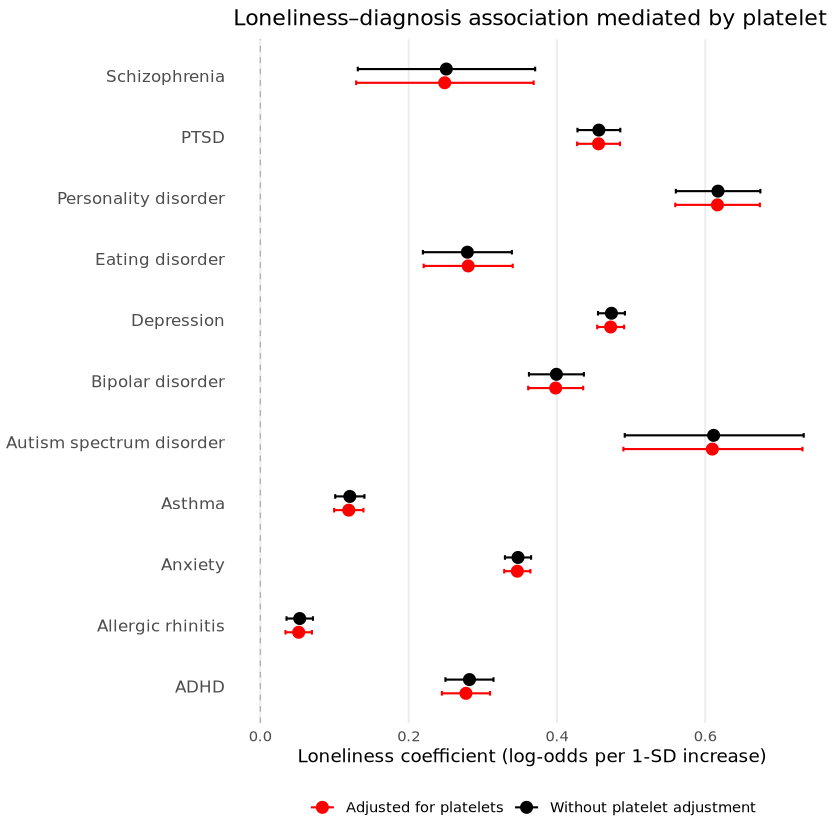

`height` was translated to `width`.


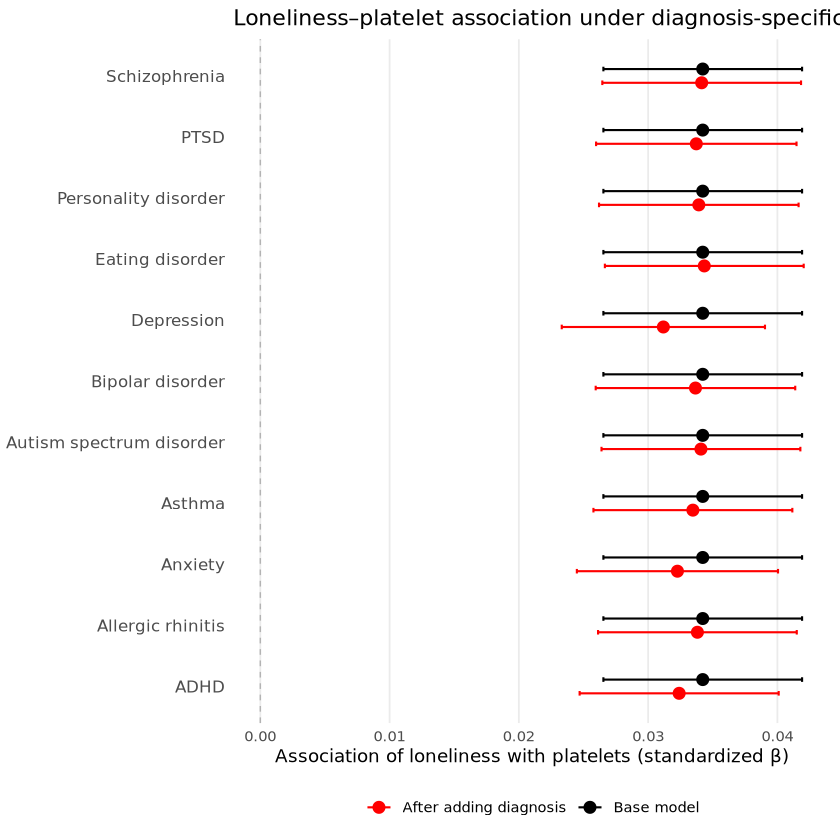

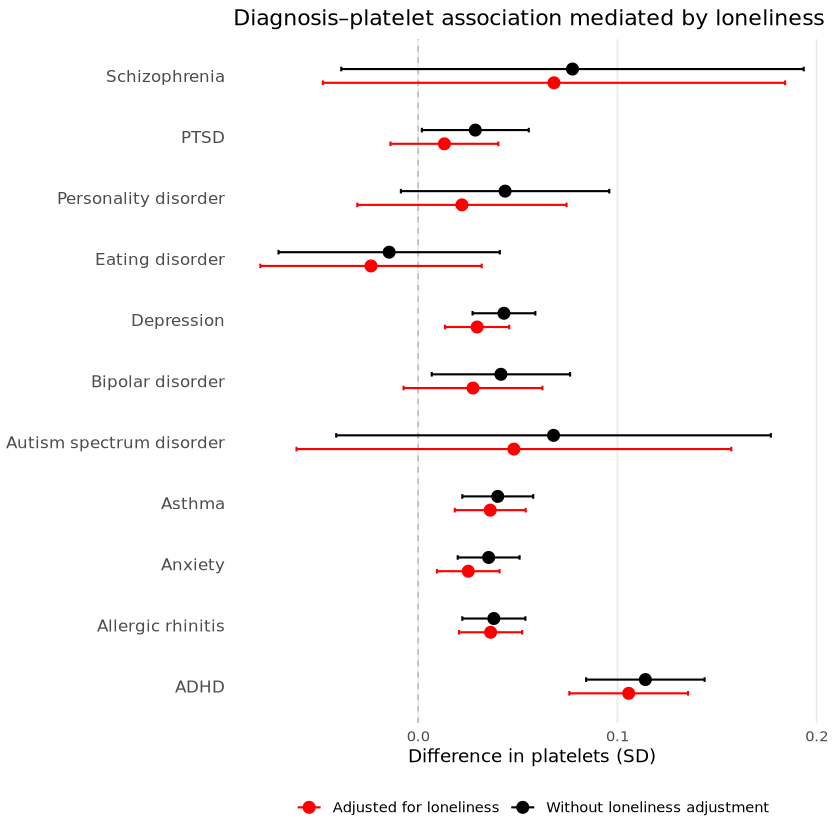

In [35]:
p1 <- make_before_after_plot(
  plot1_dat,
  title = "Loneliness–diagnosis association mediated by platelet",
  xlab = "Loneliness coefficient (log-odds per 1-SD increase)",
  before_label = "Without platelet adjustment",
  after_label = "Adjusted for platelets"
)

p1

p2 <- make_before_after_plot(
  data = plot2_dat,
  title = "Loneliness–platelet association under diagnosis-specific adjustment",
  xlab = "Association of loneliness with platelets (standardized β)",
  before_label = "Base model",
  after_label = "After adding diagnosis"
)

p2

p3 <- make_before_after_plot(
  data = plot3_dat,
  title = "Diagnosis–platelet association mediated by loneliness",
  xlab = "Difference in platelets (SD)",
  before_label = "Without loneliness adjustment",
  after_label = "Adjusted for loneliness"
)

p3

In [36]:
# Save updated p1 mediation figure
ggsave(
  "p_platelets_mediating.png",
  plot = p1,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_platelets_mediating.svg",
  plot = p1,
  width = 8,
  height = 8
)

# Save updated p2 mediation figure
ggsave(
  "p_diag_mediating.png",
  plot = p2,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_diag_mediating.svg",
  plot = p2,
  width = 8,
  height = 8
)

# Save updated p3 mediation figure
ggsave(
  "p_lone_mediating.png",
  plot = p3,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_lone_mediating.svg",
  plot = p3,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.


#### Depression / platelet mediation forest plot

Generates a six-model depression figure using the reproducible function to compare orderings across the comparisons.

`height` was translated to `width`.


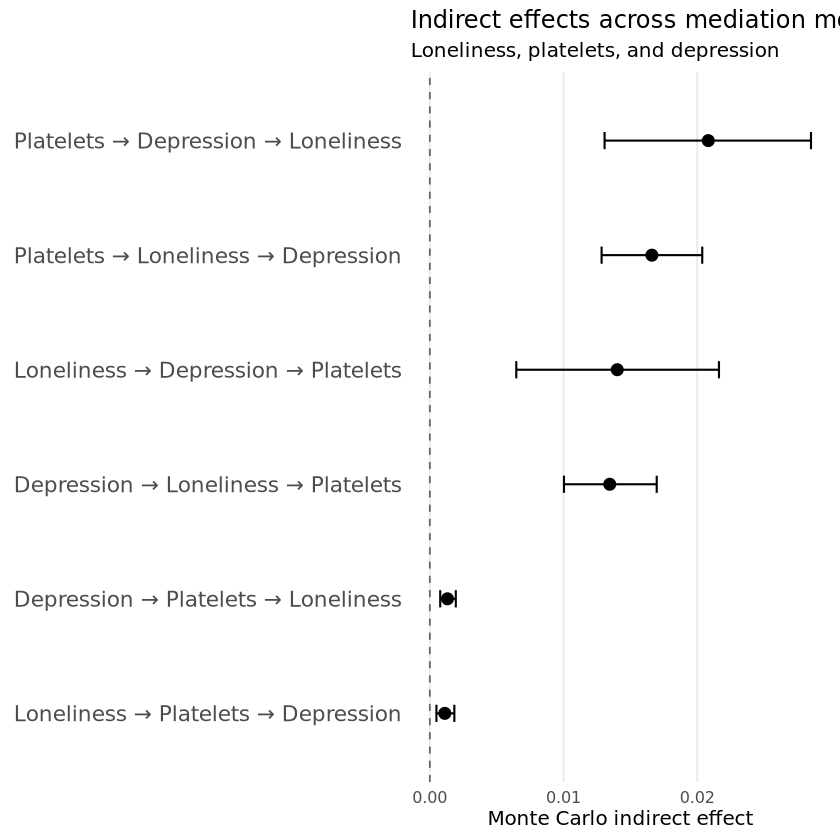

In [135]:
depression_indirect <- all_mediation_indirect %>%
  filter(phenotype_var == "depression_psych_2plus")

p_mediation_forest <- ggplot(
  depression_indirect,
  aes(
    x = estimate,
    y = reorder(pathway, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(xmin = ci_low, xmax = ci_high),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Indirect effects across mediation models",
    subtitle = "Loneliness, platelets, and depression",
    x = "Monte Carlo indirect effect",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 13),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank()
  )

p_mediation_forest

In [136]:
# Save updated depression mediation figure
ggsave(
  "p_depression_mediation_forest.png",
  plot = p_mediation_forest,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_mediation_forest.svg",
  plot = p_depression_mediation_forest,
  width = 8,
  height = 8
)

`height` was translated to `width`.


ERROR: Error: object 'p_depression_mediation_forest' not found


`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.
`height` was translated to `width`.


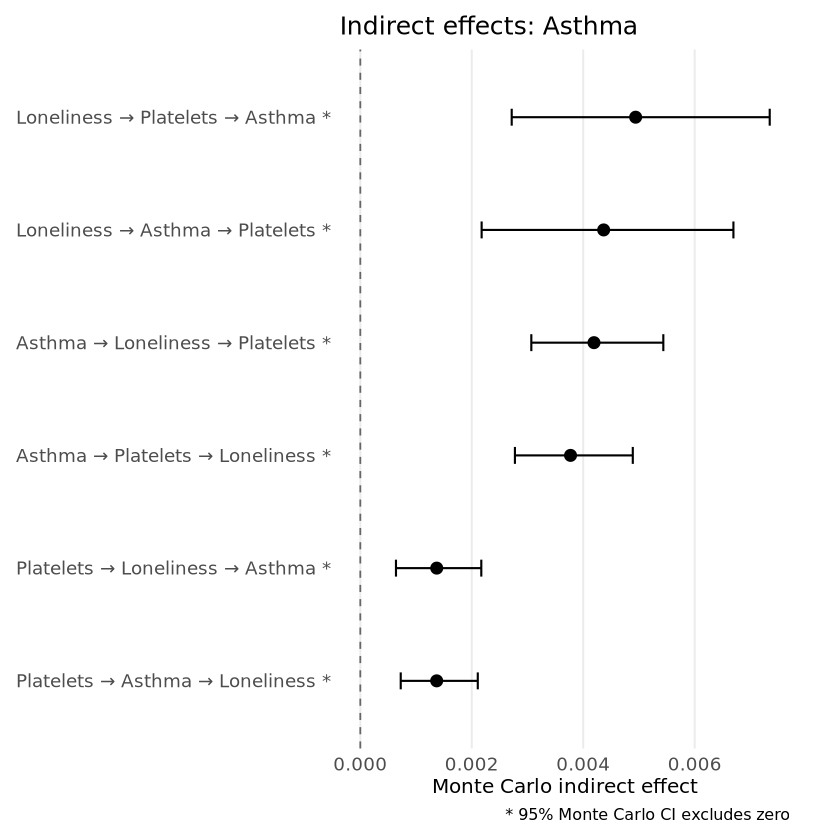

`height` was translated to `width`.
`height` was translated to `width`.


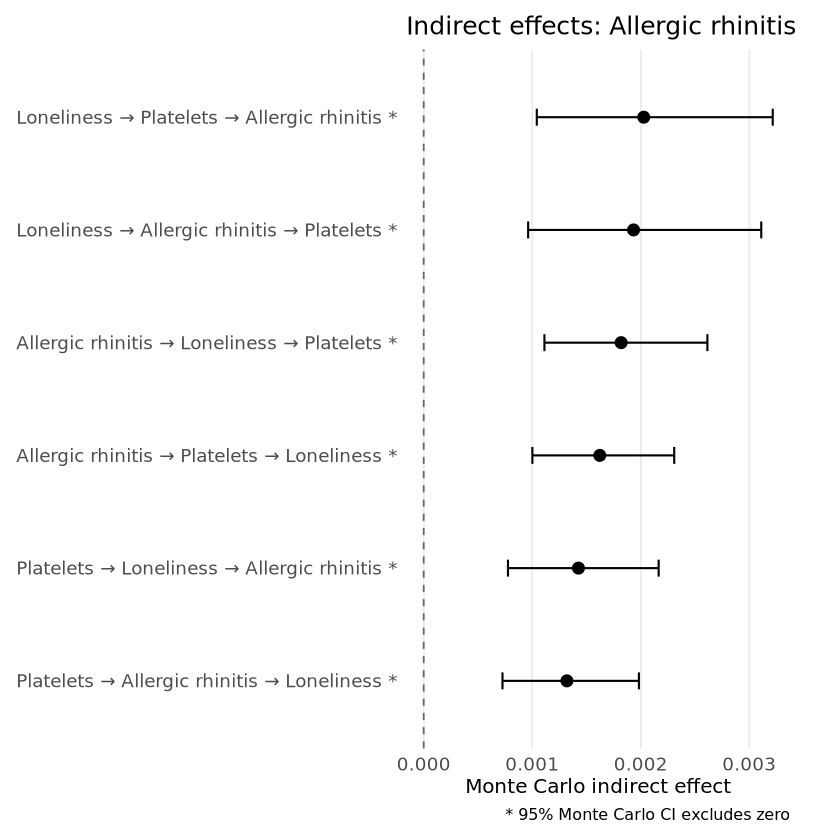

`height` was translated to `width`.
`height` was translated to `width`.


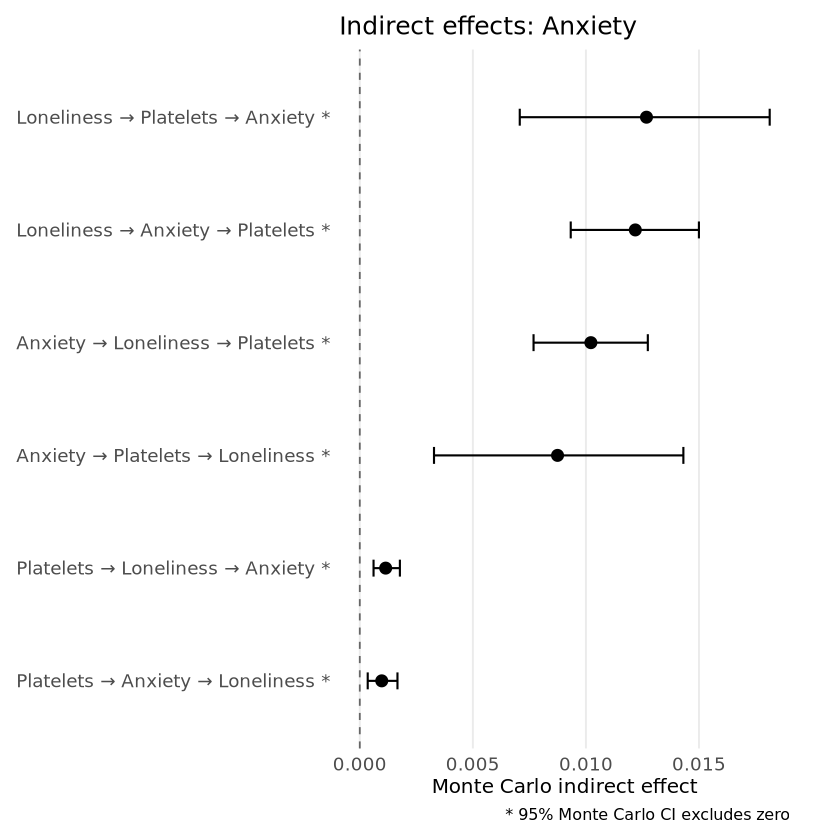

`height` was translated to `width`.
`height` was translated to `width`.


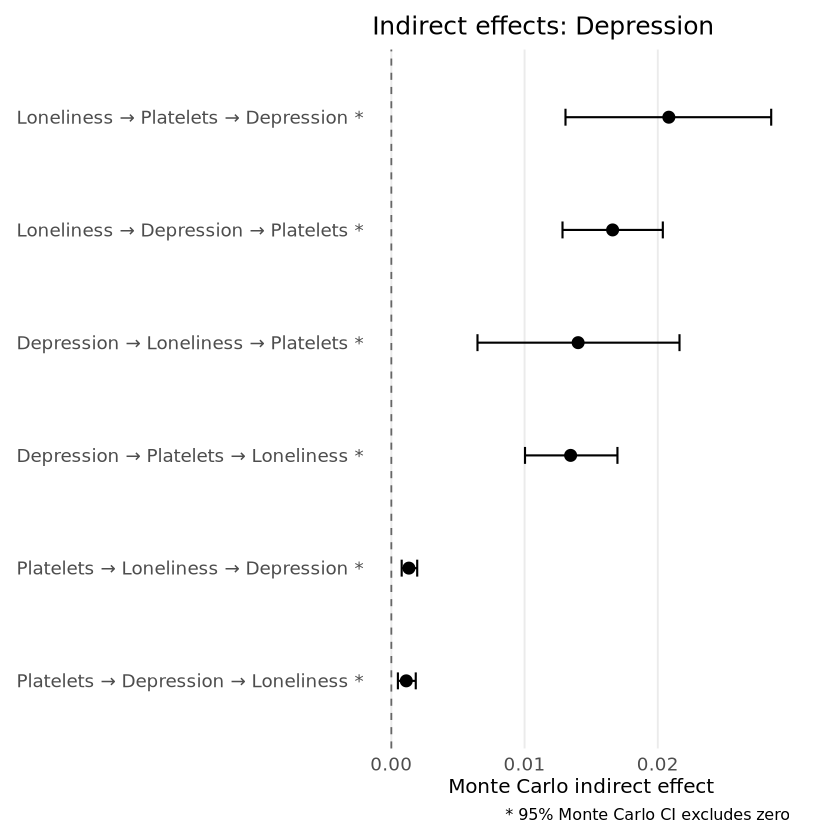

`height` was translated to `width`.
`height` was translated to `width`.


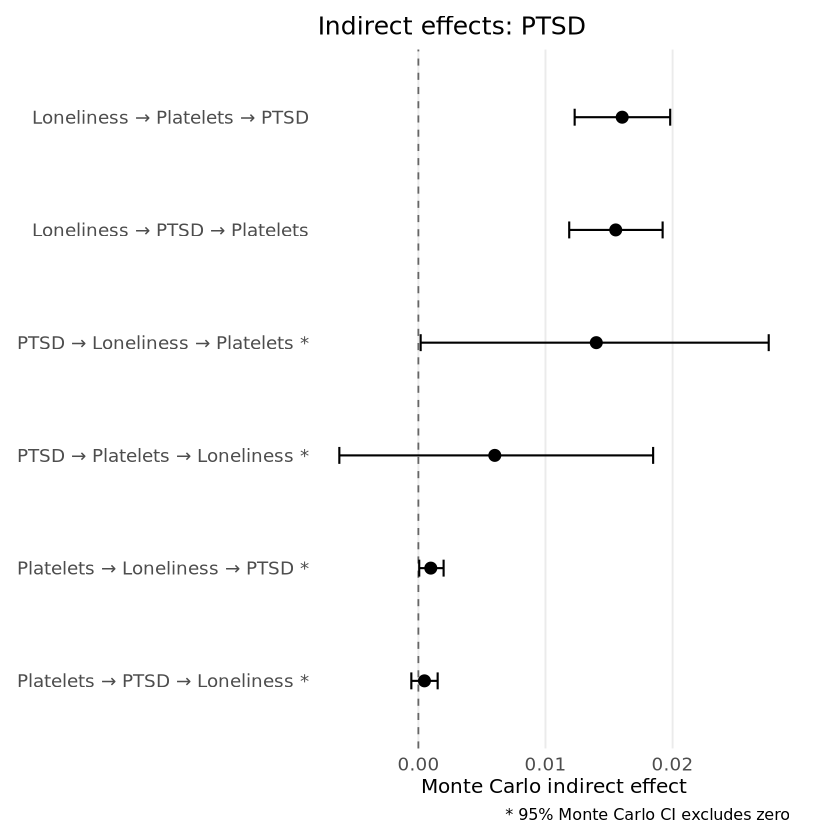

`height` was translated to `width`.
`height` was translated to `width`.


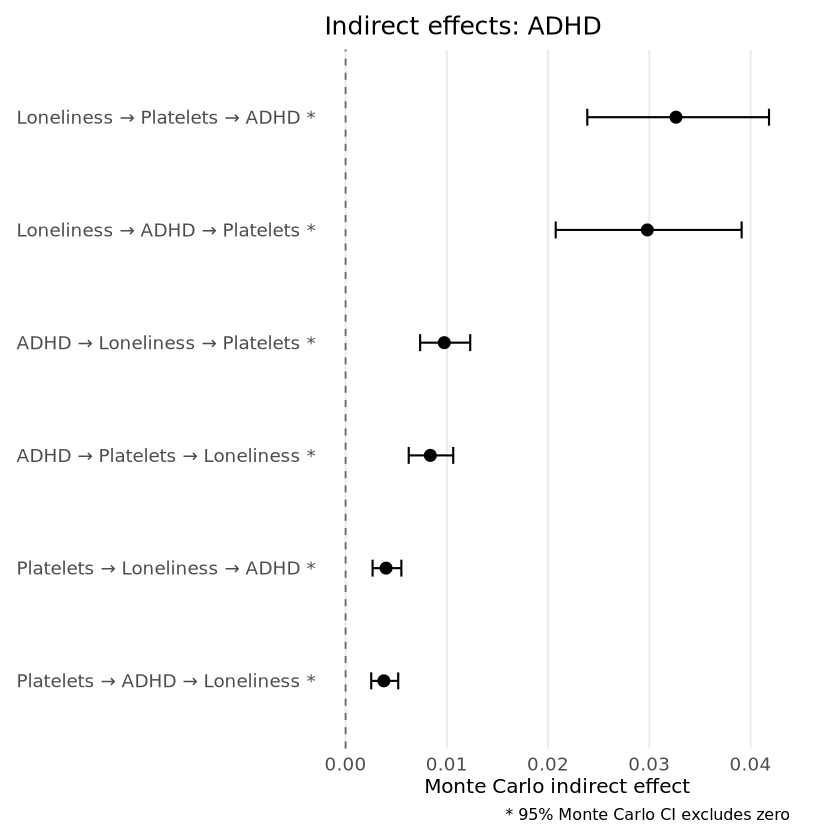

`height` was translated to `width`.
`height` was translated to `width`.


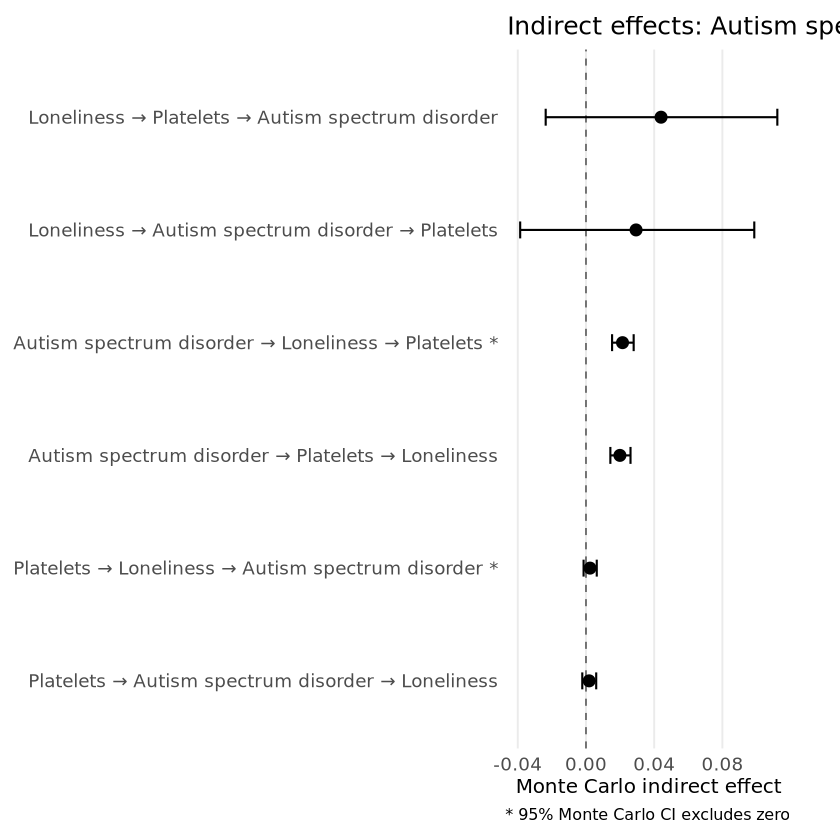

`height` was translated to `width`.
`height` was translated to `width`.


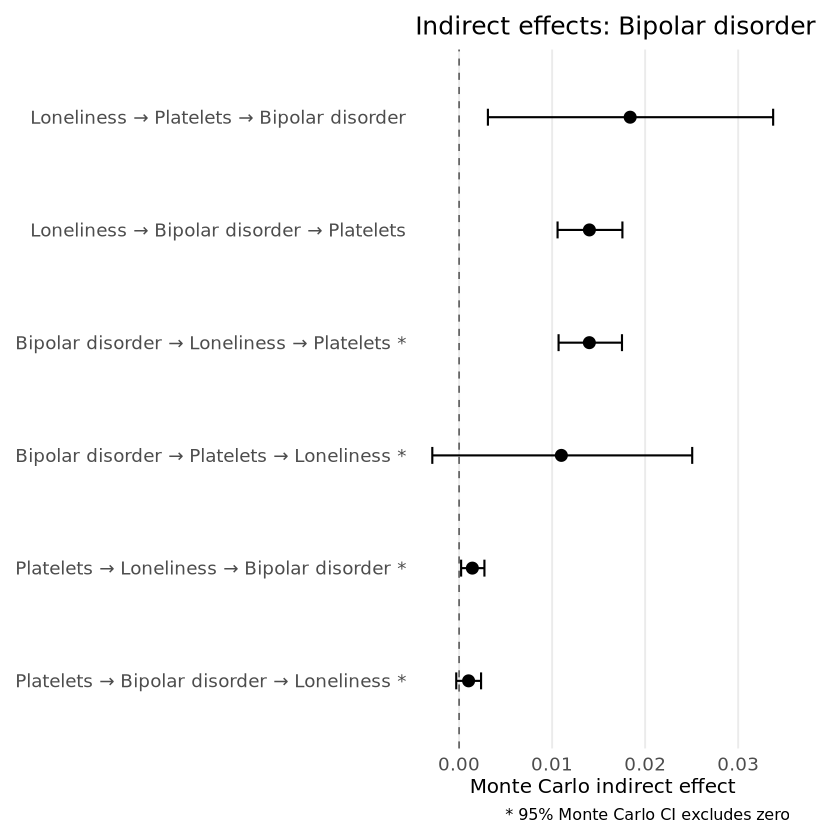

`height` was translated to `width`.
`height` was translated to `width`.


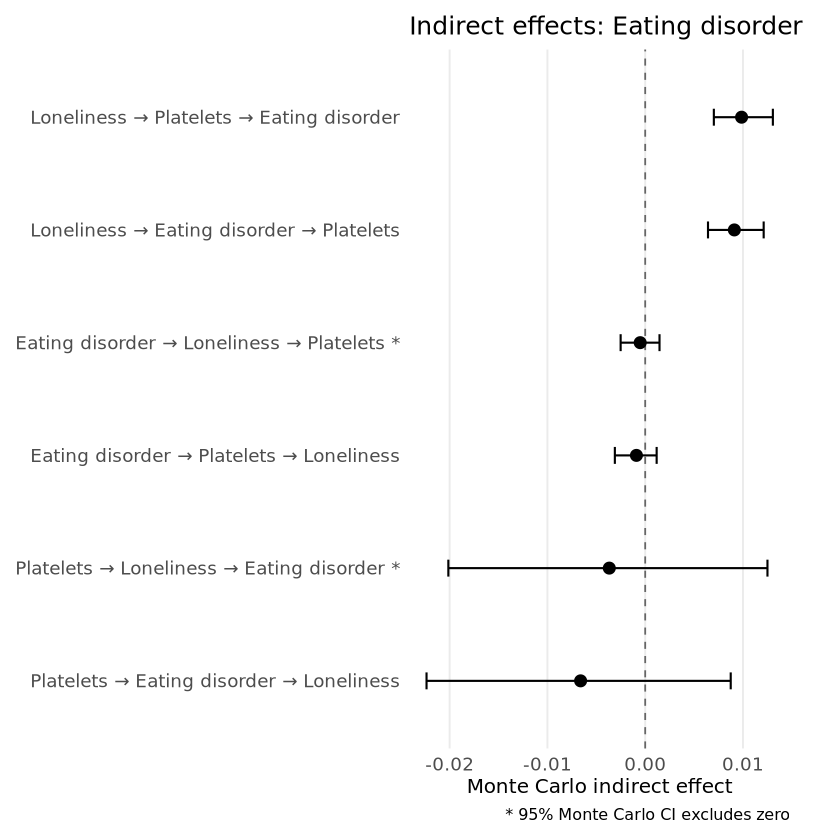

`height` was translated to `width`.
`height` was translated to `width`.


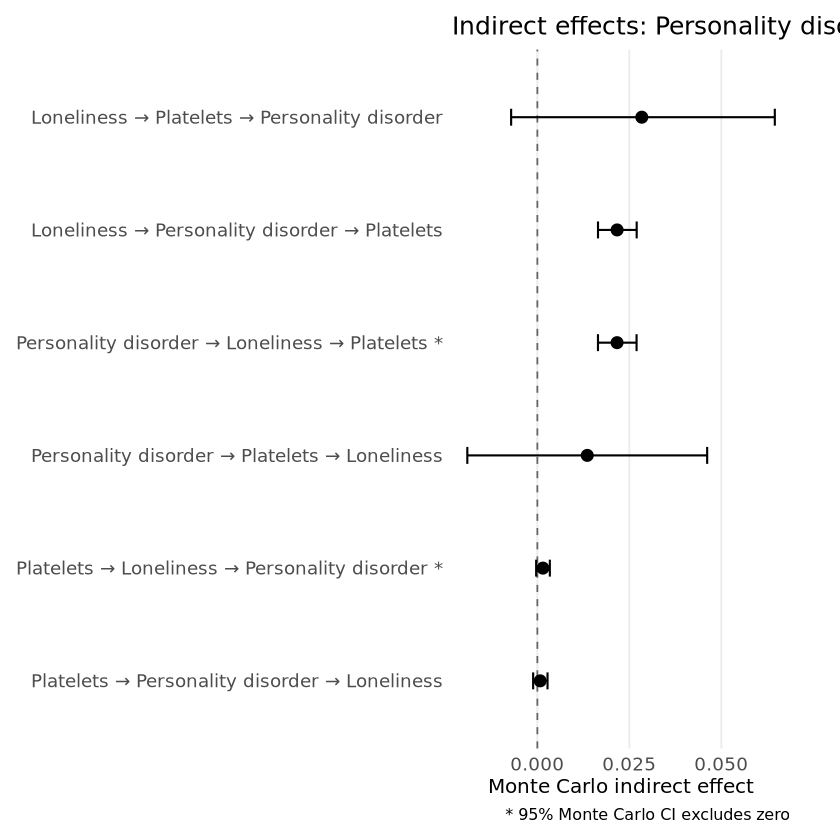

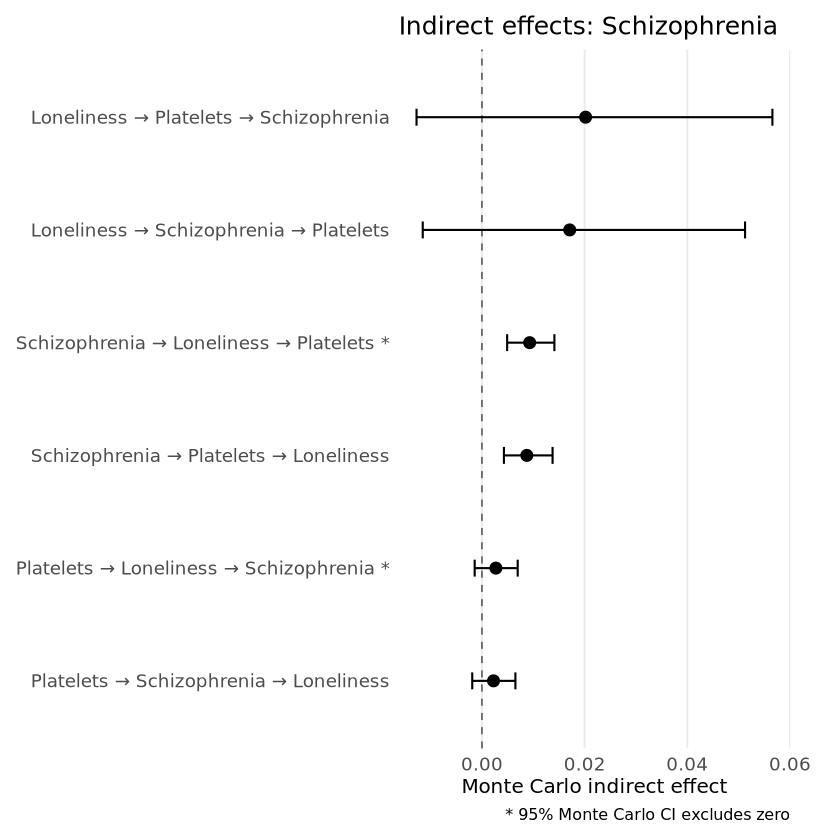

In [137]:
library(dplyr)
library(ggplot2)
library(stringr)

# Folder for individual mediation forest plots
dir.create(
  "mediation_forest_plots",
  showWarnings = FALSE
)

# Loop through each phenotype
for (i in seq_along(all_mediation_runs)) {

  # Pull indirect effects for this phenotype
  plot_dat <- all_mediation_runs[[i]]$indirect_effects

  # Phenotype name
  phenotype_name <- unique(plot_dat$phenotype)

  # Add indicator for whether 95% CI excludes zero
  plot_dat <- plot_dat %>%
    mutate(
      ci_excludes_zero = ci_low > 0 | ci_high < 0,

      plot_label = if_else(
        ci_excludes_zero,
        paste0(pathway, " *"),
        pathway
      ),

      # Keep models 1 -> 6 in a consistent order
      plot_dat <- plot_dat %>%
  arrange(desc(estimate)) %>%
  mutate(
    plot_label = factor(
      plot_label,
      levels = rev(plot_label)
    )
  )
      )


  # Make plot
  p <- ggplot(
    plot_dat,
    aes(
      x = estimate,
      y = plot_label
    )
  ) +
    geom_vline(
      xintercept = 0,
      linetype = "dashed",
      linewidth = 0.5,
      color = "grey40"
    ) +
    geom_errorbarh(
      aes(
        xmin = ci_low,
        xmax = ci_high
      ),
      height = 0.15,
      linewidth = 0.6
    ) +
    geom_point(
      size = 3,
      shape = 21,
      fill = "black",
      color = "black",
      stroke = 0.5
    ) +
    labs(
      title = paste0(
        "Indirect effects: ",
        phenotype_name
      ),
      x = "Monte Carlo indirect effect",
      y = NULL,
      caption = "* 95% Monte Carlo CI excludes zero"
    ) +
    theme_minimal(base_size = 12) +
    theme(
      axis.text.y = element_text(
        size = 11
      ),
      axis.text.x = element_text(
        size = 11
      ),
      plot.title = element_text(
        size = 15,
        hjust = 0
      ),
      panel.grid.major.y =
        element_blank(),
      panel.grid.minor =
        element_blank(),
      plot.margin =
        margin(10, 30, 10, 10)
    )

  # Display plot in notebook
  print(p)

  # Make filename safe
  safe_name <- phenotype_name %>%
    str_to_lower() %>%
    str_replace_all(
      "[^a-z0-9]+",
      "_"
    ) %>%
    str_replace_all(
      "^_|_$",
      ""
    )

  # Save plot
  ggsave(
    filename = file.path(
      "mediation_forest_plots",
      paste0(
        "mediation_forest_",
        safe_name,
        ".png"
      )
    ),
    plot = p,
    width = 9,
    height = 5.5,
    dpi = 300
  )
}

`height` was translated to `width`.


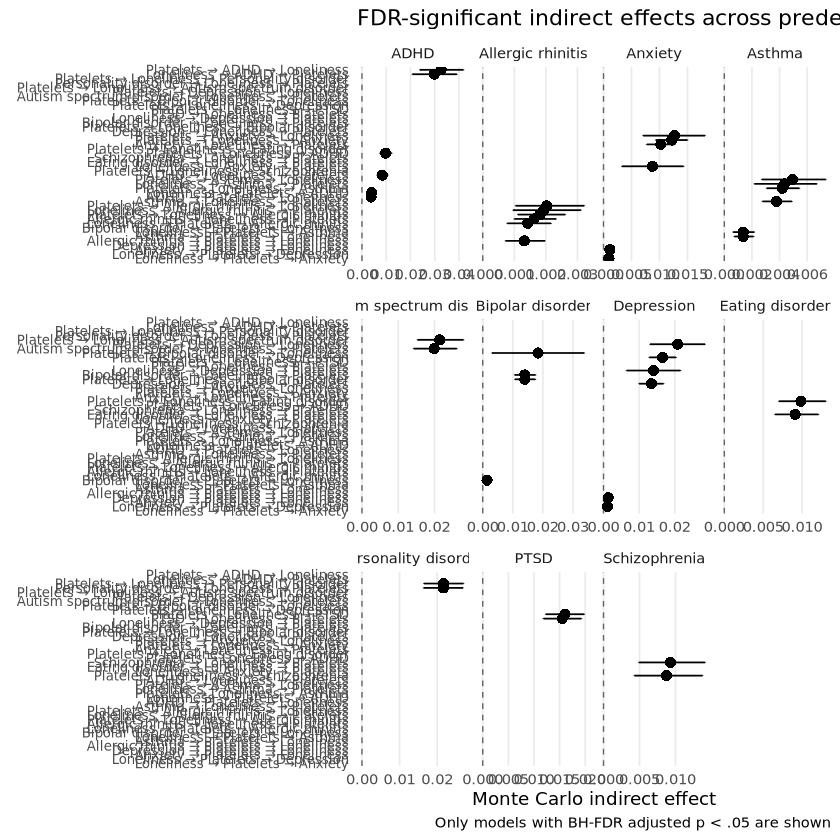

In [87]:
# One panel per phenotype, six directional models per panel

# only FDR significant models
mediation_fdr_only <- all_mediation_indirect %>%
  filter(fdr_significant) %>%
  mutate(
    pathway = droplevels(factor(pathway))
  )


p_all_mediation_forest <- ggplot(
  mediation_fdr_only,
  aes(
    x = estimate,
    y = reorder(pathway, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.4,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = ci_low,
      xmax = ci_high
    ),
    height = 0.15,
    linewidth = 0.5
  ) +
  geom_point(
    size = 2.8,
    shape = 16,
    color = "black"
  ) +
  facet_wrap(
    ~ phenotype,
    scales = "free_x"
  ) +
  labs(
    title = "FDR-significant indirect effects across predefined mediation models",
    x = "Monte Carlo indirect effect",
    y = NULL,
    caption = "Only models with BH-FDR adjusted p < .05 are shown"
  ) +
  theme_minimal(base_size = 11) +
  theme(
    axis.text.y = element_text(size = 8),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank()
  )

p_all_mediation_forest

In [138]:
# Export mediation tables for later supplement/manuscript work
write.csv(
  all_mediation_paths,
  "mediation_component_paths_all_models.csv",
  row.names = FALSE
)

write.csv(
  all_mediation_indirect,
  "mediation_indirect_effects_all_models.csv",
  row.names = FALSE
)

saveRDS(
  all_mediation_paths,
  "mediation_component_paths_all_models.rds"
)

saveRDS(
  all_mediation_indirect,
  "mediation_indirect_effects_all_models.rds"
)

ggsave(
  "p_all_mediation_forest.png",
  plot = p_all_mediation_forest,
  width = 13,
  height = 13,
  dpi = 300
)

ggsave(
  "p_all_mediation_forest.svg",
  plot = p_all_mediation_forest,
  width = 13,
  height = 13
)

system(
  'gcloud storage cp mediation_component_paths_all_models.csv "$WORKSPACE_BUCKET/workspace/conference_results"'
)
system(
  'gcloud storage cp mediation_indirect_effects_all_models.csv "$WORKSPACE_BUCKET/workspace/conference_results"'
)
system(
  'gcloud storage cp mediation_component_paths_all_models.rds "$WORKSPACE_BUCKET/workspace/conference_results"'
)
system(
  'gcloud storage cp mediation_indirect_effects_all_models.rds "$WORKSPACE_BUCKET/workspace/conference_results"'
)

`height` was translated to `width`.
`height` was translated to `width`.


In [ ]:
mediation_results <- list(
  mediation_phenotypes_to_run = mediation_phenotypes_to_run,
  all_mediation_runs = all_mediation_runs,
  all_mediation_paths = all_mediation_paths,
  all_mediation_indirect = all_mediation_indirect,
  plot1_dat = plot1_dat,
  plot2_dat = plot2_dat,
  plot3_dat = plot3_dat
)

saveRDS(
  mediation_results,
  "mediation_results.rds"
)

In [ ]:
### Compare change in estimate before vs after accounting for platelets

`height` was translated to `width`.


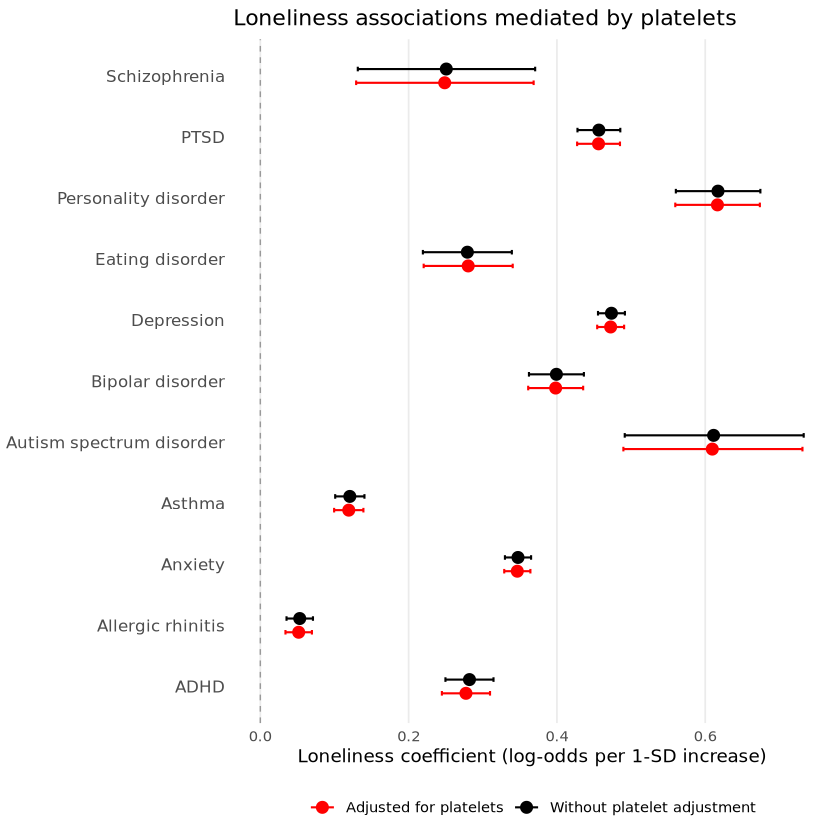

In [114]:
# comparing association with loneliness with and without indirect path through platelets
p_platelet_comparison <- ggplot(
  platelet_comparison_results,
  aes(
    x = estimate,
    y = phenotype,
    color = model
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.4,
    color = "grey60"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    position = position_dodge(width = 0.45),
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    position = position_dodge(width = 0.45)
  ) +
  scale_color_manual(
    values = c(
      "Without platelet adjustment" = "black",
      "Adjusted for platelets" = "red"
    )
  ) +
  labs(
    title = "Loneliness associations mediated by platelets",
    x = "Loneliness coefficient (log-odds per 1-SD increase)",
    y = NULL,
    color = NULL
  ) +
  theme_minimal(base_size = 11) +
  theme(
    axis.text.y = element_text(size = 10),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  )

p_platelet_comparison

- platelets do not meaningfully contribute to the association between loneliness and immune/psychiatric conditions

In [ ]:
### Exporting for Python Heatmaps
- they look nicer

In [50]:
# Variables for correlation heatmaps
psych_vars <- c(
  "anxiety_psych_2plus",
  "depression_psych_2plus",
  "ptsd_psych_2plus",
  "adhd_psych_2plus",
  "asd_psych_2plus",
  "bipolar_psych_2plus",
  "eating_disorder_psych_2plus",
  "ocd_psych_2plus",
  "personality_disorder_psych_2plus",
  "schizophrenia_psych_2plus"
)

immune_vars <- c(
  "asthma",
  "allergic_rhinitis",
  "rheumatoid_arthritis",
  "hypothyroidism",
  "ulcerative_colitis",
  "type2_diabetes",
  "crohns_disease",
  "atopic_dermatitis"
)

biomarker_vars <- c(
  "crp_z",
  "albumin_z",
  "basophils_z",
  "eosinophils_z",
  "leukocytes_z",
  "monocytes_z",
  "neutrophils_z",
  "platelets_z",
  "triglycerides_z"
)

correlation_data <- dat %>%
  select(
    person_id,
    loneliness_z,
    all_of(psych_vars),
    all_of(immune_vars),
    all_of(biomarker_vars),
    bmi,
    age_at_ucla,
    sex_at_birth,
    income_c,
    race
  )

write.csv(
  correlation_data,
  "correlation_heatmap_data.csv",
  row.names = FALSE
)

In [51]:
# save to bucket
system(
  'gcloud storage cp correlation_heatmap_data.csv "$WORKSPACE_BUCKET/workspace/cleaned_data/"'
)